## 1. Verify the dataset and the provided split

We use train.xlsx and test.xlsx without changing the train/test split.
Each ultrasound image is paired with a mask with the same filename in
the labels folder. We check for duplicate entries, overlap between the
two splits, and missing files.

In [1]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path(
    "/mnt/cv_data/users/seven/datasets/Dataset_BUSI_with_GT_Clean"
)

train_df = pd.read_excel(DATA_ROOT / "train.xlsx")
test_df = pd.read_excel(DATA_ROOT / "test.xlsx")

# Check that image names are present and unique within each split.
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    assert df["Image"].notna().all(), f"{split_name}: missing image names"
    assert df["Image"].is_unique, f"{split_name}: duplicate image names"

# The test images must not appear in the training set.
overlap = set(train_df["Image"]) & set(test_df["Image"])
assert not overlap, f"Train/test overlap: {overlap}"

# Every listed image must have a corresponding mask.
missing = []

for name in pd.concat([train_df["Image"], test_df["Image"]]):
    for folder in ["images", "labels"]:
        path = DATA_ROOT / folder / name
        if not path.is_file():
            missing.append(str(path))

assert not missing, f"Missing files: {missing[:10]}"

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Train/test filename overlap:", len(overlap))
print("All listed images and masks exist.")

Training images: 517
Testing images: 130
Train/test filename overlap: 0
All listed images and masks exist.


## 2. Visualize a training image and its segmentation mask

We display an original image, its mask, and an overlay to check spatial
alignment. The mask is read directly to preserve its palette indices
(0 and 1). The highlighted region in the overlay represents label 1.

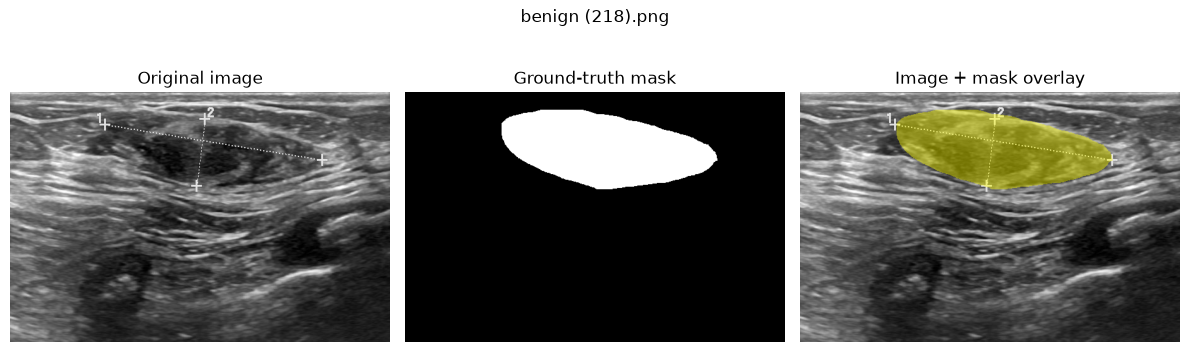

Image shape: (396, 602)
Mask values: [0 1]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Use a training example for the initial visual inspection.
name = train_df.iloc[0]["Image"]

with Image.open(DATA_ROOT / "images" / name) as img:
    image = np.array(img.convert("L"))

# Preserve the mask's original label values.
with Image.open(DATA_ROOT / "labels" / name) as img:
    mask = np.array(img)

assert mask.ndim == 2, f"Unexpected mask shape: {mask.shape}"
assert image.shape == mask.shape, "Image and mask sizes do not match."
assert set(np.unique(mask)).issubset({0, 1}), "Unexpected mask values."

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="autumn",
    alpha=0.45,
    vmin=0,
    vmax=1,
)
axes[2].set_title("Image + mask overlay")

for ax in axes:
    ax.axis("off")

fig.suptitle(name)
plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask values:", np.unique(mask))

## 3. Check the nnU-Net installation and define the folders

nnU-Net organizes its data through three folders that are read from
environment variables:

- `nnUNet_raw`: the converted dataset (Section 4);
- `nnUNet_preprocessed`: the data after nnU-Net's automatic
  preprocessing and the experiment plan it derives from the data;
- `nnUNet_results`: the trained models (weights) and training logs.

All three are placed in `outputs/nnunet/` inside the project folder. The
environment variables are set below for this notebook; the training
script sets the same values for the Slurm job. We also check that the
`nnunetv2` package is installed in the Python environment used here.

In [3]:
import importlib.util
import os
import shutil
import sys
from pathlib import Path

PROJECT_ROOT = Path("/mnt/cv_data/users/seven/Instruction3")

# Everything related to nnU-Net lives in one folder.
NNUNET_BASE = PROJECT_ROOT / "outputs" / "nnunet"
NNUNET_RAW = NNUNET_BASE / "nnUNet_raw"
NNUNET_PREPROCESSED = NNUNET_BASE / "nnUNet_preprocessed"
NNUNET_RESULTS = NNUNET_BASE / "nnUNet_results"

for folder in (NNUNET_RAW, NNUNET_PREPROCESSED, NNUNET_RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

# nnU-Net finds its folders through these environment variables.
os.environ["nnUNet_raw"] = str(NNUNET_RAW)
os.environ["nnUNet_preprocessed"] = str(NNUNET_PREPROCESSED)
os.environ["nnUNet_results"] = str(NNUNET_RESULTS)

# Dataset identifier (IDs 001-010 are reserved for public benchmark datasets).
DATASET_ID = 501
DATASET_NAME = f"Dataset{DATASET_ID:03d}_BUSI"

# Check the installation.
print("Python:", sys.executable)
if importlib.util.find_spec("nnunetv2") is None:
    print("WARNING: nnunetv2 is NOT installed in this environment.")
else:
    from importlib.metadata import version
    print("nnunetv2 version:", version("nnunetv2"))
print("nnUNetv2_train on PATH:", shutil.which("nnUNetv2_train"))

import torch
print("torch version:", torch.__version__, "| GPU available:", torch.cuda.is_available())

Python: /mnt/cv_data/users/seven/envs/ml/bin/python
nnUNetv2_train on PATH: None
torch version: 2.12.1+cu130 | GPU available: False


## 4. Convert the dataset to the nnU-Net format

nnU-Net expects its own folder layout inside `nnUNet_raw`:

- `imagesTr/`: training images, named `<case>_0000.png`, where `0000` is
  the channel index (our images have one grayscale channel);
- `labelsTr/`: training masks, named `<case>.png`, with integer labels
  (0 = background, 1 = tumor);
- `imagesTs/`: test images, used only for prediction;
- `dataset.json`: the channel names, label names, number of training
  cases and file extension.

The split comes directly from `train.xlsx` and `test.xlsx`: the training
cases are the training images and the test images are placed in
`imagesTs/`. No new split is created, and nnU-Net never sees the test
masks.

To keep the input identical to the other two models, every image is
converted to grayscale and resized to 256 × 256 (bilinear interpolation)
and every mask is resized with nearest-neighbor interpolation before it
is saved. The original filenames contain spaces and brackets, so each
case receives a simple identifier (`BUSI_0001`, ...). A mapping table is
saved so that predictions can be renamed to the original filenames later.
The `zscore` channel name tells nnU-Net to normalize each image by its
own mean and standard deviation, which is its default for non-CT images.
Note that this normalization is chosen by nnU-Net and differs from the
[0, 1] scaling used for U-Net and DeepLabV3+.

In [4]:
import json
import numpy as np
import pandas as pd
from PIL import Image

IMAGE_SIZE = (256, 256)

DATASET_DIR = NNUNET_RAW / DATASET_NAME
images_tr = DATASET_DIR / "imagesTr"
labels_tr = DATASET_DIR / "labelsTr"
images_ts = DATASET_DIR / "imagesTs"

train_names = train_df["Image"].tolist()
test_names = test_df["Image"].tolist()

# Give every image a simple case identifier and remember the original name.
records = []
case_number = 1
for split, names in (("train", train_names), ("test", test_names)):
    for name in names:
        records.append({"split": split, "case_id": f"BUSI_{case_number:04d}", "image_name": name})
        case_number += 1
mapping_df = pd.DataFrame(records)

OVERWRITE = False   # set to True to rebuild the dataset from scratch

if DATASET_DIR.exists() and not OVERWRITE:
    print("Dataset folder already exists; skipping conversion:", DATASET_DIR)
else:
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)
    for folder in (images_tr, labels_tr, images_ts):
        folder.mkdir(parents=True)

    for row in mapping_df.itertuples():
        # Image: grayscale, 256 x 256, bilinear, saved as an 8-bit PNG.
        with Image.open(DATA_ROOT / "images" / row.image_name) as img:
            img = img.convert("L").resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
            target = images_tr if row.split == "train" else images_ts
            img.save(target / f"{row.case_id}_0000.png")

        # Mask (training cases only): labels 0/1, nearest-neighbor resize.
        if row.split == "train":
            with Image.open(DATA_ROOT / "labels" / row.image_name) as label:
                assert set(np.unique(np.array(label))).issubset({0, 1}), row.image_name
                label = label.resize(IMAGE_SIZE, resample=Image.Resampling.NEAREST)
                Image.fromarray(np.array(label, dtype=np.uint8)).save(labels_tr / f"{row.case_id}.png")

    # dataset.json describes the dataset to nnU-Net.
    dataset_json = {
        "channel_names": {"0": "zscore"},               # one channel, z-score normalization
        "labels": {"background": 0, "tumor": 1},
        "numTraining": len(train_names),
        "file_ending": ".png",
    }
    with open(DATASET_DIR / "dataset.json", "w") as file:
        json.dump(dataset_json, file, indent=2)

# Save the mapping between case identifiers and original filenames.
mapping_df.to_csv(NNUNET_BASE / "case_mapping.csv", index=False)

# Verify the converted dataset.
train_ids = mapping_df.loc[mapping_df["split"] == "train", "case_id"].tolist()
test_ids = mapping_df.loc[mapping_df["split"] == "test", "case_id"].tolist()

assert len(list(images_tr.glob("*_0000.png"))) == len(train_ids) == len(train_names)
assert len(list(labels_tr.glob("*.png"))) == len(train_ids)
assert len(list(images_ts.glob("*_0000.png"))) == len(test_ids) == len(test_names)
assert all((labels_tr / f"{cid}.png").is_file() for cid in train_ids)
assert not set(train_names) & set(test_names), "Train/test overlap"

# Look at one converted training case.
first_id = train_ids[0]
sample_image = np.array(Image.open(images_tr / f"{first_id}_0000.png"))
sample_label = np.array(Image.open(labels_tr / f"{first_id}.png"))
print("Training cases:", len(train_ids), "| Test cases:", len(test_ids))
print("Example", first_id, "->", mapping_df.iloc[0]["image_name"])
print("Image:", sample_image.shape, sample_image.dtype, "| Label:", sample_label.shape, np.unique(sample_label))
print(json.dumps(json.load(open(DATASET_DIR / "dataset.json")), indent=2))

Dataset folder already exists; skipping conversion: /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/nnUNet_raw/Dataset501_BUSI
Training cases: 517 | Test cases: 130
Example BUSI_0001 -> benign (218).png
Image: (256, 256) uint8 | Label: (256, 256) [0 1]
{
  "channel_names": {
    "0": "zscore"
  },
  "labels": {
    "background": 0,
    "tumor": 1
  },
  "numTraining": 517,
  "file_ending": ".png"
}


## 5. Plan the experiment and preprocess the data

This is the automatic configuration step of nnU-Net. The command
`nnUNetv2_plan_and_preprocess` does three things:

1. It checks the dataset format (`--verify_dataset_integrity`): file
   names, image and label shapes, and that the label values are
   consecutive integers.
2. It extracts a "fingerprint" of the training data (image sizes,
   intensity statistics, class frequencies).
3. From the fingerprint it derives a plan (patch size, batch size,
   network depth, normalization) and preprocesses the training images
   into its own format.

We only need the 2D configuration (`-c 2d`), because the images are
2D. The step uses the CPU and takes a few minutes. It is skipped if the
plan already exists, unless `REDO = True`.

In [5]:
import subprocess
import sys

# nnU-Net is installed in its own environment, separate from the one running this notebook.
NNUNET_ENV_BIN = Path("/mnt/cv_data/users/seven/envs/nnunet/bin")
BIN_DIR = NNUNET_ENV_BIN if (NNUNET_ENV_BIN / "nnUNetv2_plan_and_preprocess").is_file() \
    else Path(sys.executable).parent
print("nnU-Net executables in:", BIN_DIR)


def run(command):
    """Run a command, show its output live and stop if it fails."""
    env = os.environ.copy()
    env["PATH"] = f"{BIN_DIR}{os.pathsep}{env['PATH']}"
    print("$", " ".join(str(part) for part in command), flush=True)
    process = subprocess.Popen(
        command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env
    )
    for line in process.stdout:
        print(line, end="")
    if process.wait() != 0:
        raise RuntimeError(f"Command failed with exit code {process.returncode}")


PLANS_PATH = NNUNET_PREPROCESSED / DATASET_NAME / "nnUNetPlans.json"
REDO = False   # set to True to plan and preprocess again

if PLANS_PATH.is_file() and not REDO:
    print("Plan already exists; skipping:", PLANS_PATH)
else:
    run([
        BIN_DIR / "nnUNetv2_plan_and_preprocess",
        "-d", str(DATASET_ID),          # dataset 501
        "-c", "2d",                     # only the 2D configuration
        "--verify_dataset_integrity",   # check the converted dataset
        "-np", "4",                     # number of preprocessing processes
        "--no_pbar",                    # no progress bar (cleaner notebook output)
    ])

assert PLANS_PATH.is_file(), "nnUNetPlans.json was not created"
print("\nPlan file:", PLANS_PATH)

nnU-Net executables in: /mnt/cv_data/users/seven/envs/nnunet/bin
Plan already exists; skipping: /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/nnUNet_preprocessed/Dataset501_BUSI/nnUNetPlans.json

Plan file: /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/nnUNet_preprocessed/Dataset501_BUSI/nnUNetPlans.json


## 6. Review the plan and align the batch size

nnU-Net has chosen the network and training configuration automatically.
We print the 2D configuration to document what it decided: patch size,
batch size, normalization and network architecture.

To follow the fairness rule of this project as far as possible, we
overwrite only the batch size with 8, the value used for U-Net and
DeepLabV3+. nnU-Net's own choice is kept in a backup file
(`nnUNetPlans_original.json`) and shown below. Everything else in the
plan stays as nnU-Net decided; in particular, the optimizer (SGD with
Nesterov momentum), the learning-rate schedule, the normalization
(z-score) and the data augmentation cannot be matched to the other
models and are documented in Section 7. Set `FORCE_BATCH_SIZE = None` to
keep nnU-Net's own batch size.

In [6]:
import json

FORCE_BATCH_SIZE = 8     # same batch size as U-Net and DeepLabV3+; None = keep nnU-Net's choice

backup_path = PLANS_PATH.with_name("nnUNetPlans_original.json")

with open(PLANS_PATH) as file:
    plans = json.load(file)

# Keep nnU-Net's own plan once, before any change is made.
if not backup_path.exists():
    shutil.copy(PLANS_PATH, backup_path)
with open(backup_path) as file:
    automatic_plans = json.load(file)

automatic_cfg = automatic_plans["configurations"]["2d"]
print("nnU-Net's automatic 2D configuration:")
print(json.dumps(automatic_cfg, indent=2))
print("\nAutomatic batch size:", automatic_cfg["batch_size"])
print("Automatic patch size:", automatic_cfg["patch_size"])

# Overwrite only the batch size; this must happen before training starts.
if FORCE_BATCH_SIZE is not None:
    plans["configurations"]["2d"]["batch_size"] = FORCE_BATCH_SIZE
else:
    plans["configurations"]["2d"]["batch_size"] = automatic_cfg["batch_size"]
with open(PLANS_PATH, "w") as file:
    json.dump(plans, file, indent=2)

print("Batch size used for training:", plans["configurations"]["2d"]["batch_size"])

nnU-Net's automatic 2D configuration:
{
  "data_identifier": "nnUNetPlans_2d",
  "preprocessor_name": "DefaultPreprocessor",
  "batch_size": 26,
  "patch_size": [
    256,
    256
  ],
  "median_image_size_in_voxels": [
    256.0,
    256.0
  ],
  "spacing": [
    1.0,
    1.0
  ],
  "normalization_schemes": [
    "ZScoreNormalization"
  ],
  "use_mask_for_norm": [
    false
  ],
  "resampling_fn_data": "resample_data_or_seg_to_shape",
  "resampling_fn_seg": "resample_data_or_seg_to_shape",
  "resampling_fn_data_kwargs": {
    "is_seg": false,
    "order": 3,
    "order_z": 0,
    "force_separate_z": null
  },
  "resampling_fn_seg_kwargs": {
    "is_seg": true,
    "order": 1,
    "order_z": 0,
    "force_separate_z": null
  },
  "resampling_fn_probabilities": "resample_data_or_seg_to_shape",
  "resampling_fn_probabilities_kwargs": {
    "is_seg": false,
    "order": 1,
    "order_z": 0,
    "force_separate_z": null
  },
  "architecture": {
    "network_class_name": "dynamic_network_ar

## 7. Train nnU-Net on the allocated GPU

Training is started with the following command, which is run inside the
script `train_nnunet.py` and submitted to a GPU node through Slurm:

```
nnUNetv2_train 501 2d all -tr nnUNetTrainer_50epochs
```

- `501` is the dataset, `2d` the configuration.
- `all` trains on all training cases, so no validation split is created
  and the test set is never used. As for the other models, the weights
  of the final epoch (`checkpoint_final.pth`) are used.
- `nnUNetTrainer_50epochs` trains for 50 epochs, the same epoch number as
  U-Net and DeepLabV3+.

Some settings cannot be made identical to the other two models, because
nnU-Net configures itself automatically:

| Setting | U-Net / DeepLabV3+ | nnU-Net |
|---|---|---|
| Normalization | scaling to [0, 1] | z-score per image |
| Optimizer | Adam, learning rate 0.001 | SGD with Nesterov momentum, learning rate 0.01 with polynomial decay |
| Loss | 0.5 BCE + 0.5 soft Dice | Dice + cross-entropy (with deep supervision) |
| Data augmentation | none | nnU-Net's default augmentation (rotation, scaling, mirroring, noise, brightness, contrast, gamma) |
| Length of an epoch | 65 iterations (one pass over the data) | 250 iterations, so about 12,500 iterations in total |
| Random seed | fixed to 42 | cannot be set from the command line |
| Batch size | 8 | 8 (overwritten in Section 6) |

The test images are not used in training or planning. They are only
used for prediction after training. The script is printed below so that
the training procedure is documented in this notebook.

## 8. Locate the trained model and review the training log

nnU-Net stores its results in `nnUNet_results`, in a folder named after
the trainer, the plan and the configuration. With `all` as the fold, the
folder `fold_all` contains the final weights (`checkpoint_final.pth`),
the training log and a plot of the training curves (`progress.png`).

To keep the deliverables organized as for the other models, the final
weights and the plan files are copied into a separate `weights/` folder,
and the predicted masks will be stored in a separate `pred_masks/`
folder (Section 9).

Note that with `all` as the fold, nnU-Net has no validation set. The
"validation" values in its log and plot are computed on the training
images themselves, so they show training performance, not
generalization.

Model folder: /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/nnUNet_results/Dataset501_BUSI/nnUNetTrainer_50epochs__nnUNetPlans__2d
Files in fold_all: ['checkpoint_best.pth', 'checkpoint_final.pth', 'debug.json', 'progress.png', 'training_log_2026_10_29_09_33_34.txt', 'validation']
Weights copied to: /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/weights

Last lines of training_log_2026_10_29_09_33_34.txt
2026-10-29 09:53:51.207339: predicting BUSI_0513 
2026-10-29 09:53:51.207862: BUSI_0513, shape torch.Size([1, 1, 256, 256]), rank 0 
2026-10-29 09:53:51.226665: predicting BUSI_0514 
2026-10-29 09:53:51.227342: BUSI_0514, shape torch.Size([1, 1, 256, 256]), rank 0 
2026-10-29 09:53:51.246352: predicting BUSI_0515 
2026-10-29 09:53:51.247127: BUSI_0515, shape torch.Size([1, 1, 256, 256]), rank 0 
2026-10-29 09:53:51.265693: predicting BUSI_0516 
2026-10-29 09:53:51.266443: BUSI_0516, shape torch.Size([1, 1, 256, 256]), rank 0 
2026-10-29 09:53:51.286217: predicting BUSI_051

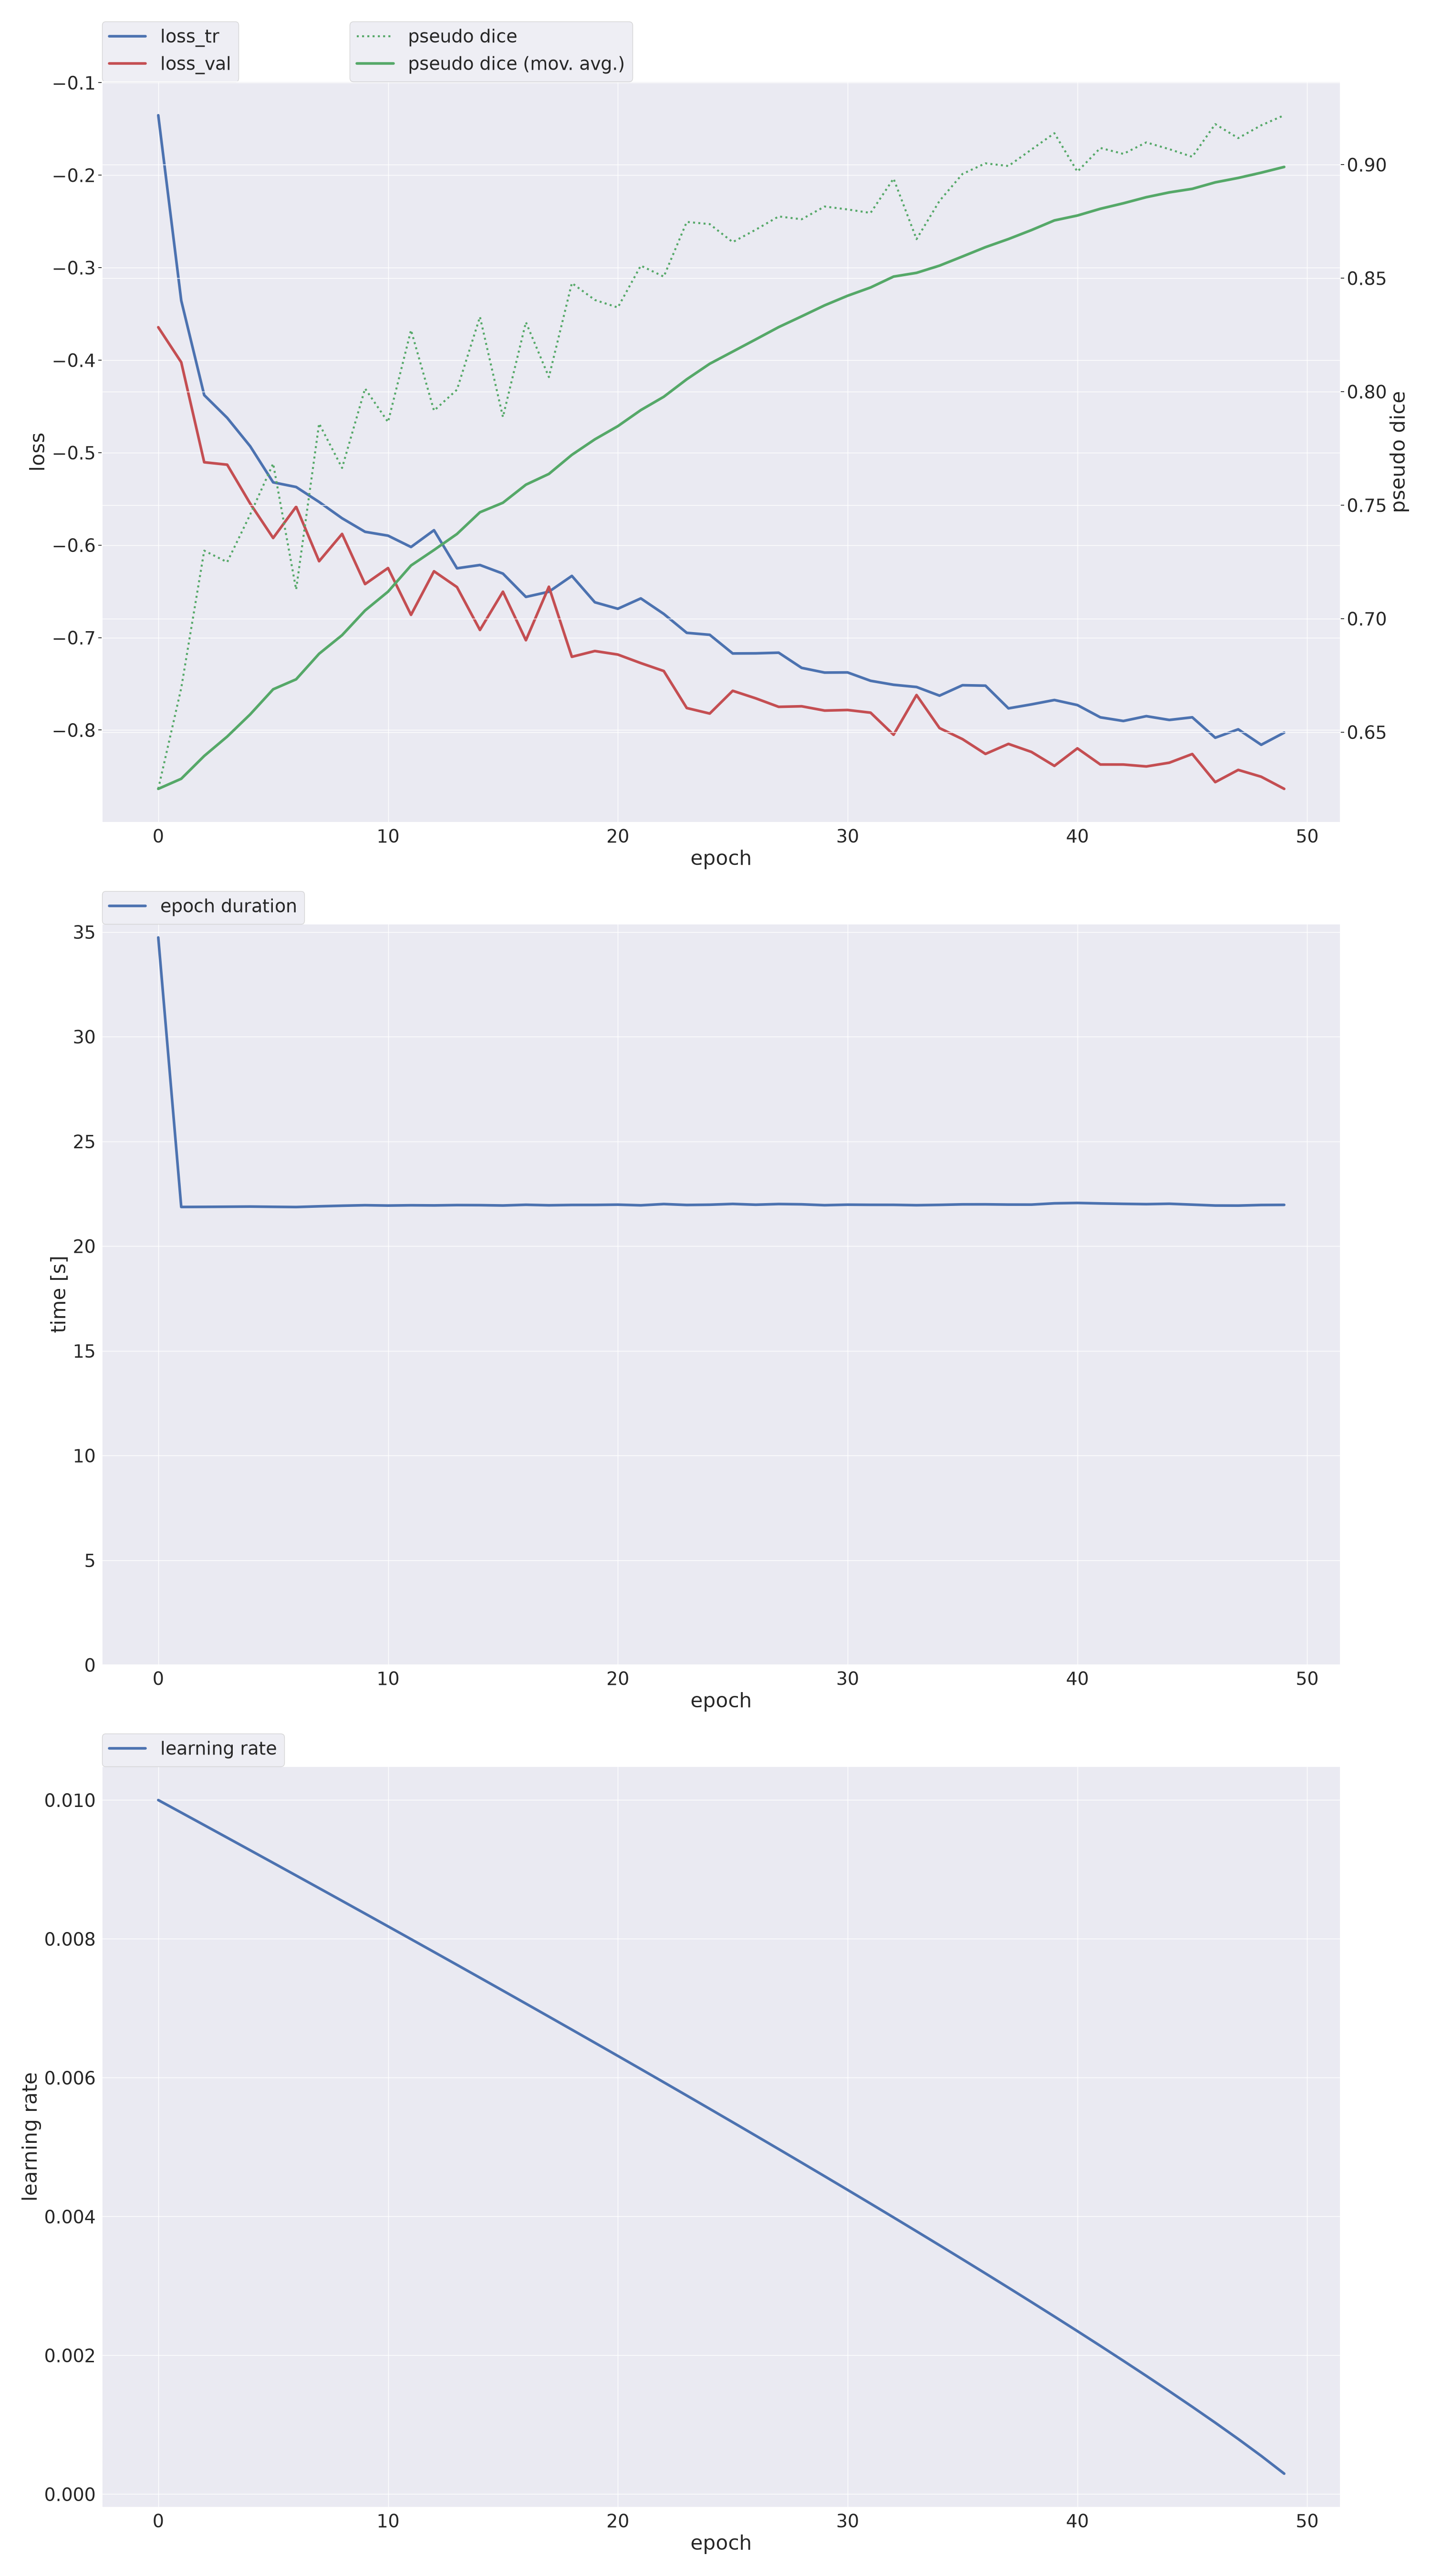

In [7]:
from IPython.display import Image as IPyImage, display

TRAINER = "nnUNetTrainer_50epochs"
MODEL_DIR = NNUNET_RESULTS / DATASET_NAME / f"{TRAINER}__nnUNetPlans__2d"
FOLD_DIR = MODEL_DIR / "fold_all"
CHECKPOINT = FOLD_DIR / "checkpoint_final.pth"

if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Final weights not found (is training finished?): {CHECKPOINT}")

# Everything that belongs to the nnU-Net experiment is stored below this folder.
RUN_DIR = NNUNET_BASE

# Copy the final weights and the plan files into their own folder.
WEIGHTS_DIR = RUN_DIR / "weights"
WEIGHTS_DIR.mkdir(exist_ok=True)
shutil.copy(CHECKPOINT, WEIGHTS_DIR / "nnunet_final.pth")
for name in ["plans.json", "dataset.json", "dataset_fingerprint.json"]:
    if (MODEL_DIR / name).is_file():
        shutil.copy(MODEL_DIR / name, WEIGHTS_DIR / name)

print("Model folder:", MODEL_DIR)
print("Files in fold_all:", sorted(p.name for p in FOLD_DIR.iterdir()))
print("Weights copied to:", WEIGHTS_DIR)

# Last lines of the training log: loss and learning rate of the final epochs.
log_files = sorted(FOLD_DIR.glob("training_log_*.txt"))
if log_files:
    print("\nLast lines of", log_files[-1].name)
    print("\n".join(log_files[-1].read_text().splitlines()[-12:]))

# Training curves saved by nnU-Net.
if (FOLD_DIR / "progress.png").is_file():
    display(IPyImage(filename=str(FOLD_DIR / "progress.png")))

## 9. Predict the test set and save the predicted masks

nnU-Net predicts with its own command, `nnUNetv2_predict`. It reads the
test images from `imagesTs/`, applies the same preprocessing as in
training, runs the trained model and writes one segmentation file per
case. By default, nnU-Net also uses test-time augmentation: it averages
the predictions for mirrored versions of each image. This is part of the
standard nnU-Net pipeline and the other two models do not use it; set
`USE_TTA = False` to switch it off.

nnU-Net names its output files by case identifier (`BUSI_0518.png`) and
stores tumor pixels as 1. We convert every prediction back to a binary
mask with the original image filename (tumor = 255, background = 0) and
store it in the separate folder `pred_masks/`. The raw nnU-Net outputs are
kept in `predictions_raw/`. The test images are used only here, for
prediction.

In [8]:
USE_TTA = True          # nnU-Net's default inference uses test-time augmentation
REPREDICT = False       # set to True to run the prediction again

RAW_PRED_DIR = NNUNET_BASE / "predictions_raw"
PRED_DIR = RUN_DIR / "pred_masks"
RAW_PRED_DIR.mkdir(exist_ok=True)
PRED_DIR.mkdir(exist_ok=True)

device_name = "cuda" if torch.cuda.is_available() else "cpu"   # 130 small images are fine on CPU
print("Prediction device:", device_name)

if REPREDICT or len(list(RAW_PRED_DIR.glob("BUSI_*.png"))) == 0:
    command = [
        BIN_DIR / "nnUNetv2_predict",
        "-i", str(images_ts),                # test images in nnU-Net format
        "-o", str(RAW_PRED_DIR),             # raw nnU-Net predictions
        "-d", str(DATASET_ID),
        "-c", "2d",
        "-f", "all",                         # model trained on all training cases
        "-tr", TRAINER,
        "-chk", "checkpoint_final.pth",      # weights of the final epoch
        "-device", device_name,
        "-npp", "1", "-nps", "1",            # few worker processes (shared login node)
    ]
    if not USE_TTA:
        command.append("--disable_tta")
    run(command)

# Convert the raw predictions into binary masks with the original filenames.
test_mapping = mapping_df[mapping_df["split"] == "test"]
saved_names = []
for row in test_mapping.itertuples():
    raw = np.array(Image.open(RAW_PRED_DIR / f"{row.case_id}.png"))
    assert raw.shape == (256, 256), f"Unexpected shape for {row.case_id}"
    assert set(np.unique(raw)).issubset({0, 1}), f"Unexpected labels for {row.case_id}"
    mask = (raw > 0).astype(np.uint8) * 255          # tumor = 255, background = 0
    Image.fromarray(mask).save(PRED_DIR / row.image_name, format="PNG")
    saved_names.append(row.image_name)

# Sanity checks: every test image has a prediction, in the order of test.xlsx.
assert saved_names == test_names, "Saved predictions do not match test.xlsx"
print(f"Saved {len(saved_names)} predicted masks to {PRED_DIR}")

empty = sum(not np.array(Image.open(PRED_DIR / n)).any() for n in test_names)
print(f"Images with an empty predicted mask: {empty} / {len(test_names)}")

Prediction device: cpu
$ /mnt/cv_data/users/seven/envs/nnunet/bin/nnUNetv2_predict -i /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/nnUNet_raw/Dataset501_BUSI/imagesTs -o /mnt/cv_data/users/seven/Instruction3/outputs/nnunet/predictions_raw -d 501 -c 2d -f all -tr nnUNetTrainer_50epochs -chk checkpoint_final.pth -device cpu -npp 1 -nps 1

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

perform_everything_on_device=True is only supported for cuda devices! Setting this to False
Error importing huggingface_hub.hf_api: No module named 'filelock'
There are 130 cases in the source folder
I am process 0 out of 1 (max process ID is 0, we st

## 10. Evaluate with Dice, IoU and HD95

We compare each predicted mask with its ground-truth mask using three
standard segmentation metrics. Let P be the predicted tumor region and
G the ground-truth tumor region.

- **Dice coefficient** = 2|P ∩ G| / (|P| + |G|). It measures the overlap
  between prediction and ground truth, from 0 (no overlap) to 1
  (perfect). Higher is better.
- **Intersection over Union (IoU)** = |P ∩ G| / |P ∪ G|. It is also an
  overlap measure, but stricter than Dice because the denominator is the
  union. Higher is better.
- **HD95 (95th-percentile Hausdorff distance)** is the 95th percentile of
  the distances (in pixels) between the boundary of P and the boundary
  of G, taken in both directions. It measures boundary error: a small
  value means the predicted outline is close to the true outline. Using
  the 95th percentile instead of the maximum makes it robust to a few
  outlier pixels. Lower is better.

Dice and IoU focus on region overlap, while HD95 focuses on boundary
accuracy, so together they give a more complete picture.

All three models use the same `evaluate.py` and the same conventions,
computed on the 256 × 256 masks. If both masks are empty, Dice = IoU = 1
and HD95 = 0. If only one of them is empty, Dice and IoU are 0 and HD95
is undefined; those images are excluded from the HD95 average and their
number is reported. The per-image results are saved to `metrics.csv`.

In [9]:
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import evaluate

IMG_DIR = DATA_ROOT / "images"
GT_DIR = DATA_ROOT / "labels"

# Per-image Dice, IoU and HD95, with mean ± std printed over the test set.
metrics_df = evaluate.evaluate_folder(
    pred_dir=PRED_DIR,
    gt_dir=GT_DIR,
    names=test_names,
    save_csv=RUN_DIR / "metrics.csv",
)

# Test-set averages (these are the numbers for the comparison table).
summary = metrics_df[["dice", "iou", "hd95"]].agg(["mean", "std"]).round(4)
display(summary)

# Inspect images where the model predicted no tumor at all.
for name in test_names:
    pred_area = int(evaluate.load_mask(PRED_DIR / name).sum())
    gt_area = int(evaluate.load_mask(GT_DIR / name).sum())
    if pred_area == 0:
        print(f"Empty prediction: {name} | ground-truth tumor pixels: {gt_area}")

# Show the 5 test images with the lowest Dice for a first look at failures.
display(metrics_df.sort_values("dice").head(5).round(4))

Dice : 0.8245 ± 0.2204
IoU  : 0.7436 ± 0.2309
HD95 : 20.92 ± 29.78 px (2 images with undefined HD95 skipped)


,dice,iou,hd95
mean,0.8245,0.7436,20.9218
std,0.2204,0.2309,29.7782


Empty prediction: benign (122).png | ground-truth tumor pixels: 2074
Empty prediction: benign (108).png | ground-truth tumor pixels: 2025


,name,dice,iou,hd95
40,benign (122).png,0.0000,0.0000,NaN
116,benign (108).png,0.0000,0.0000,NaN
96,malignant (45).png,0.0128,0.0064,128.5146
42,malignant (181).png,0.0220,0.0111,147.3550
108,malignant (157).png,0.0261,0.0132,110.9491


## 11. Visualize the test results

Numbers alone do not show where a model fails, so we display every test
image in pages of eight. Each row contains four panels:

1. the original ultrasound image;
2. the ground-truth mask;
3. the predicted mask (the per-image Dice score is in the title);
4. an overlay on the original image with color-coded errors:
   - **yellow**: correctly predicted tumor (true positive),
   - **red**: predicted tumor that is not in the ground truth (false
     positive, i.e. over-segmentation),
   - **green**: tumor in the ground truth that the model missed (false
     negative, i.e. under-segmentation).

When reviewing the images, look for missed tumors, over- or
under-segmented regions, and inaccurate boundaries. The figures are also
saved as PNG files so they can be reused in `segmentation_comparison.md`.

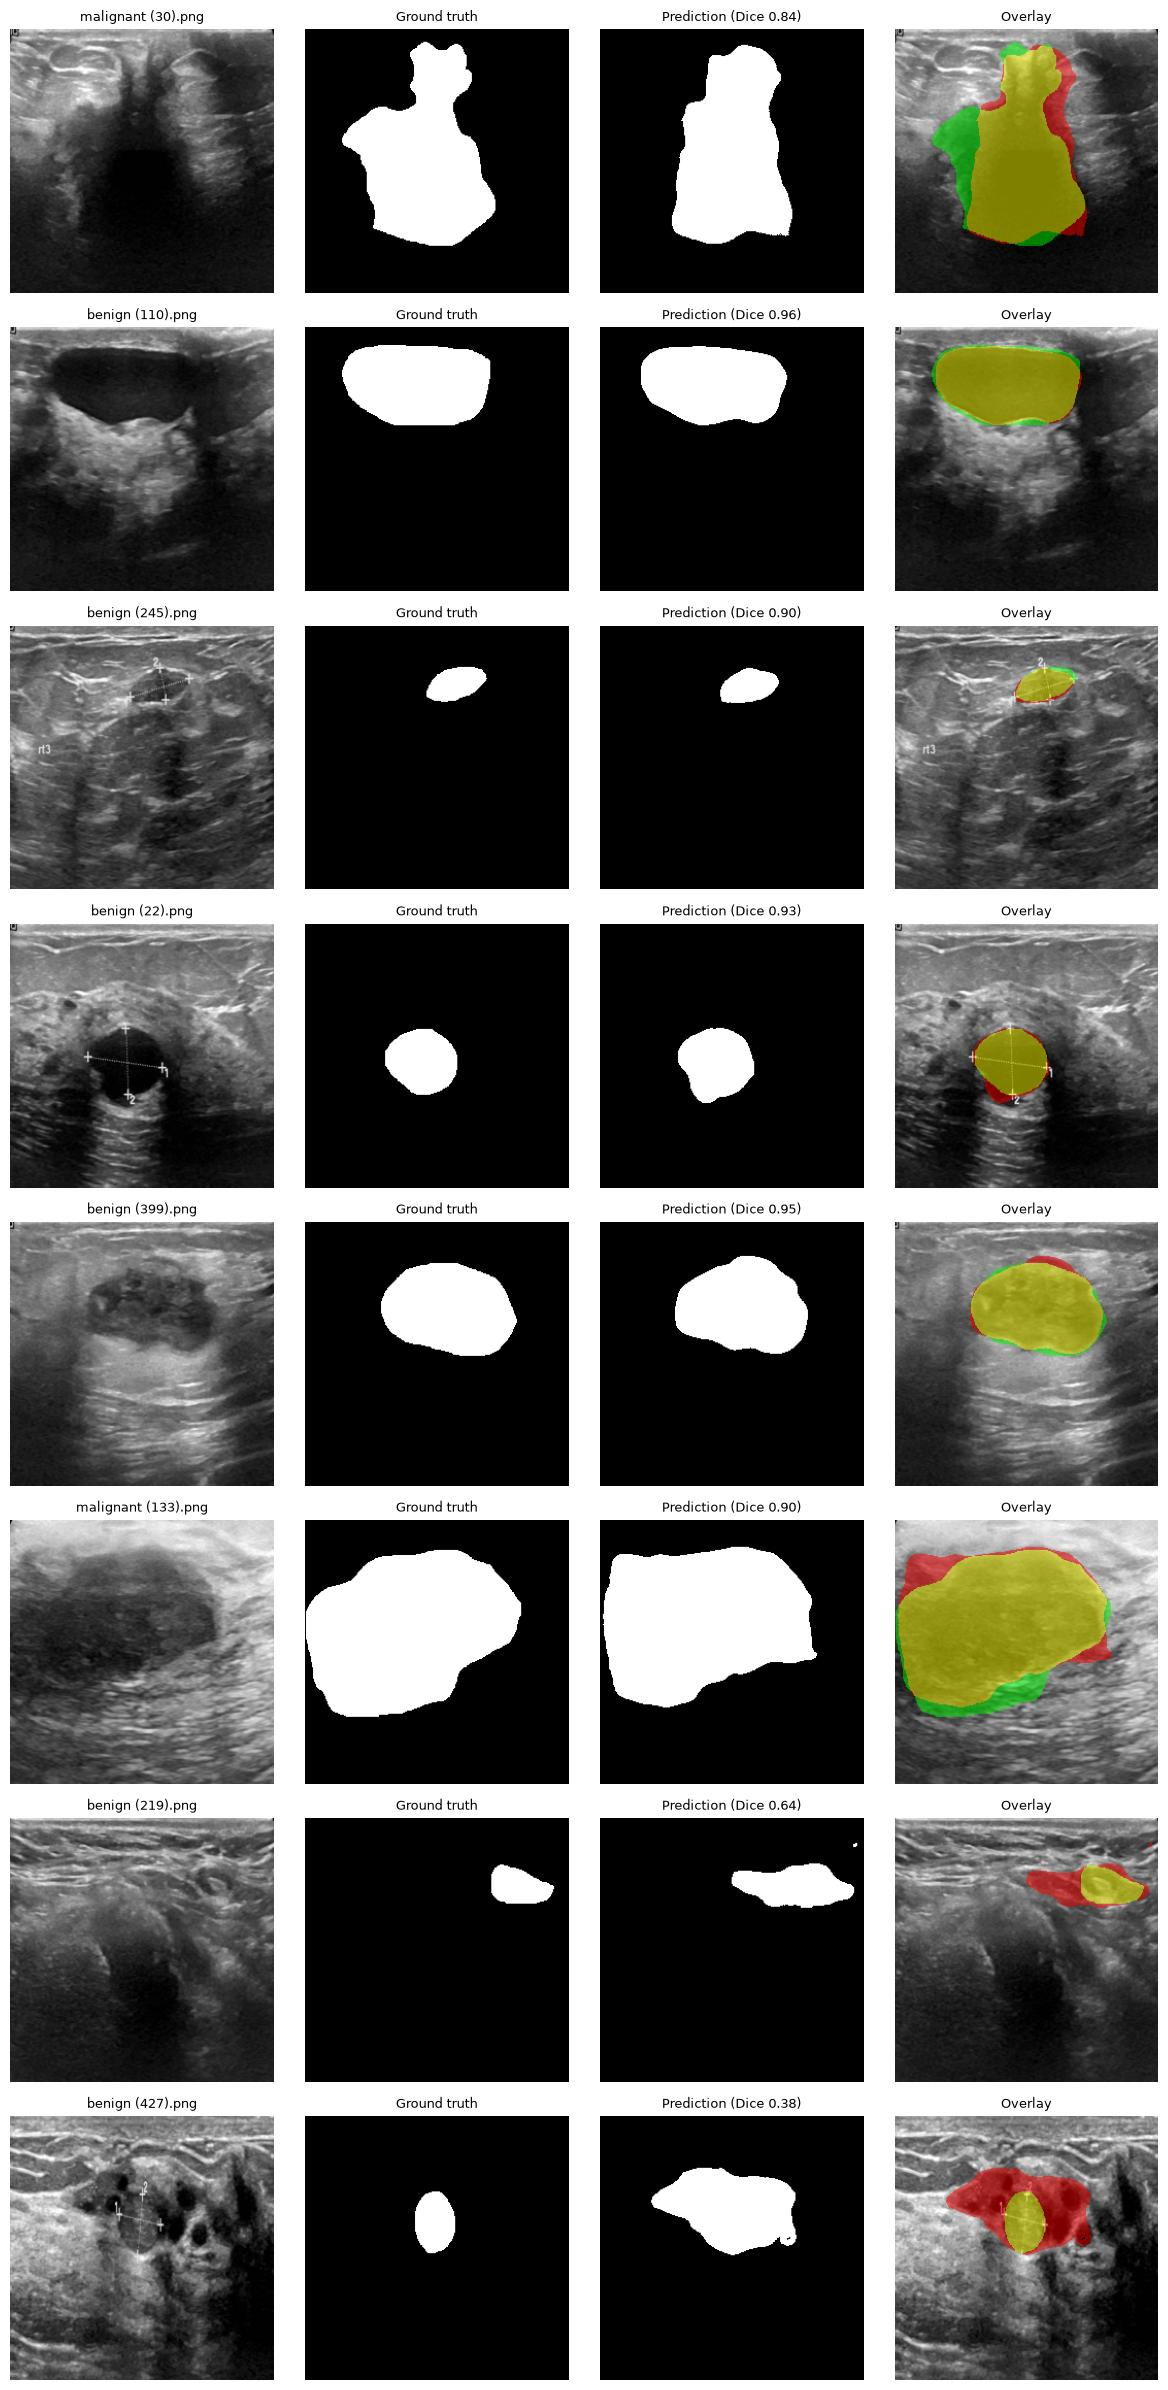

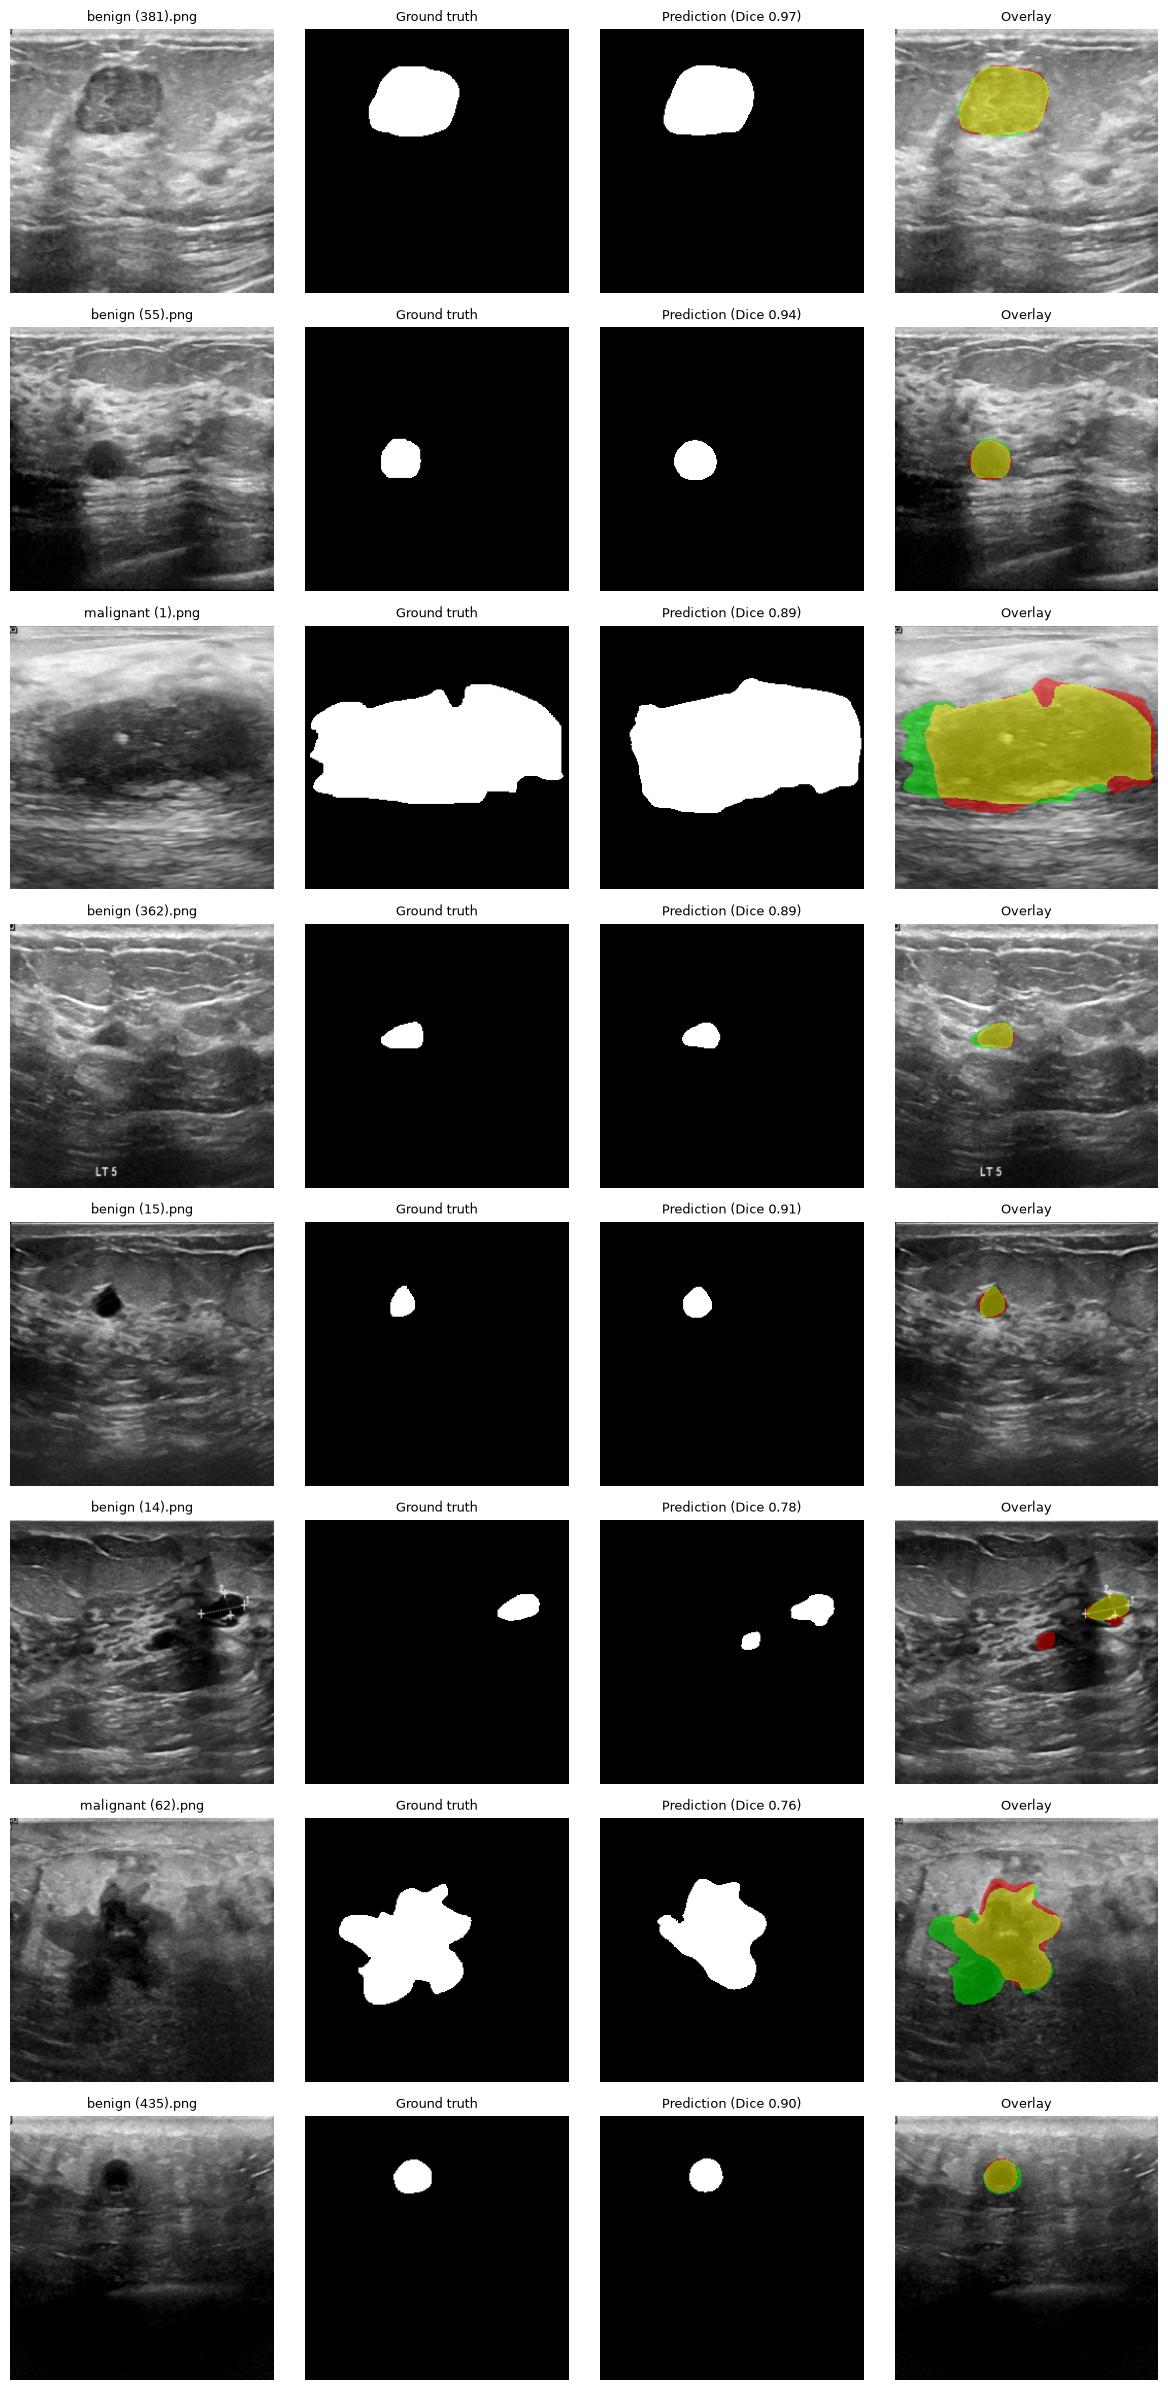

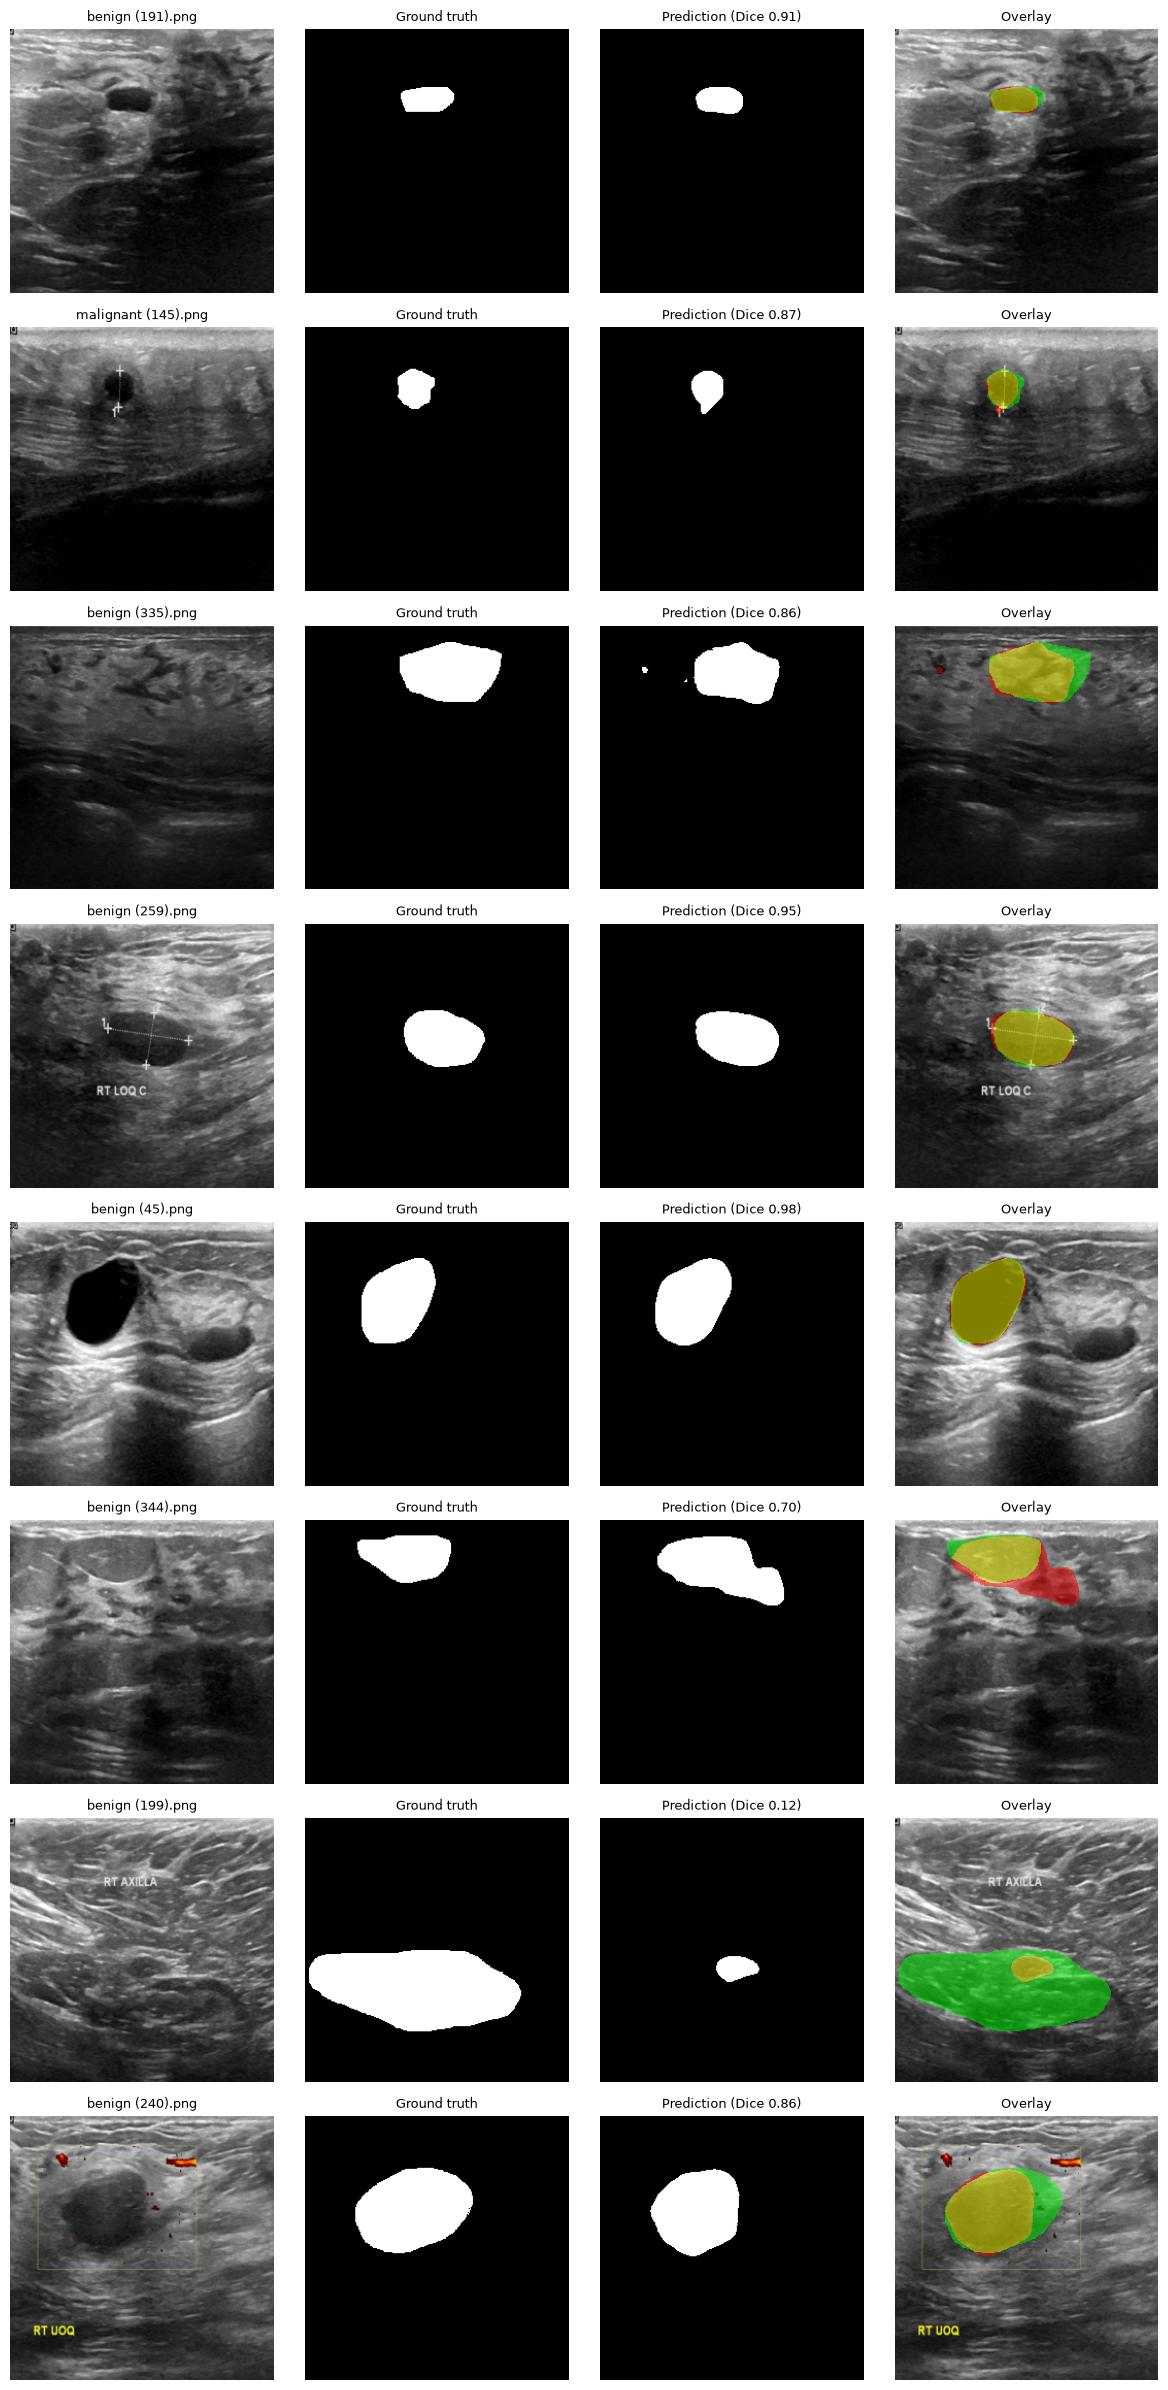

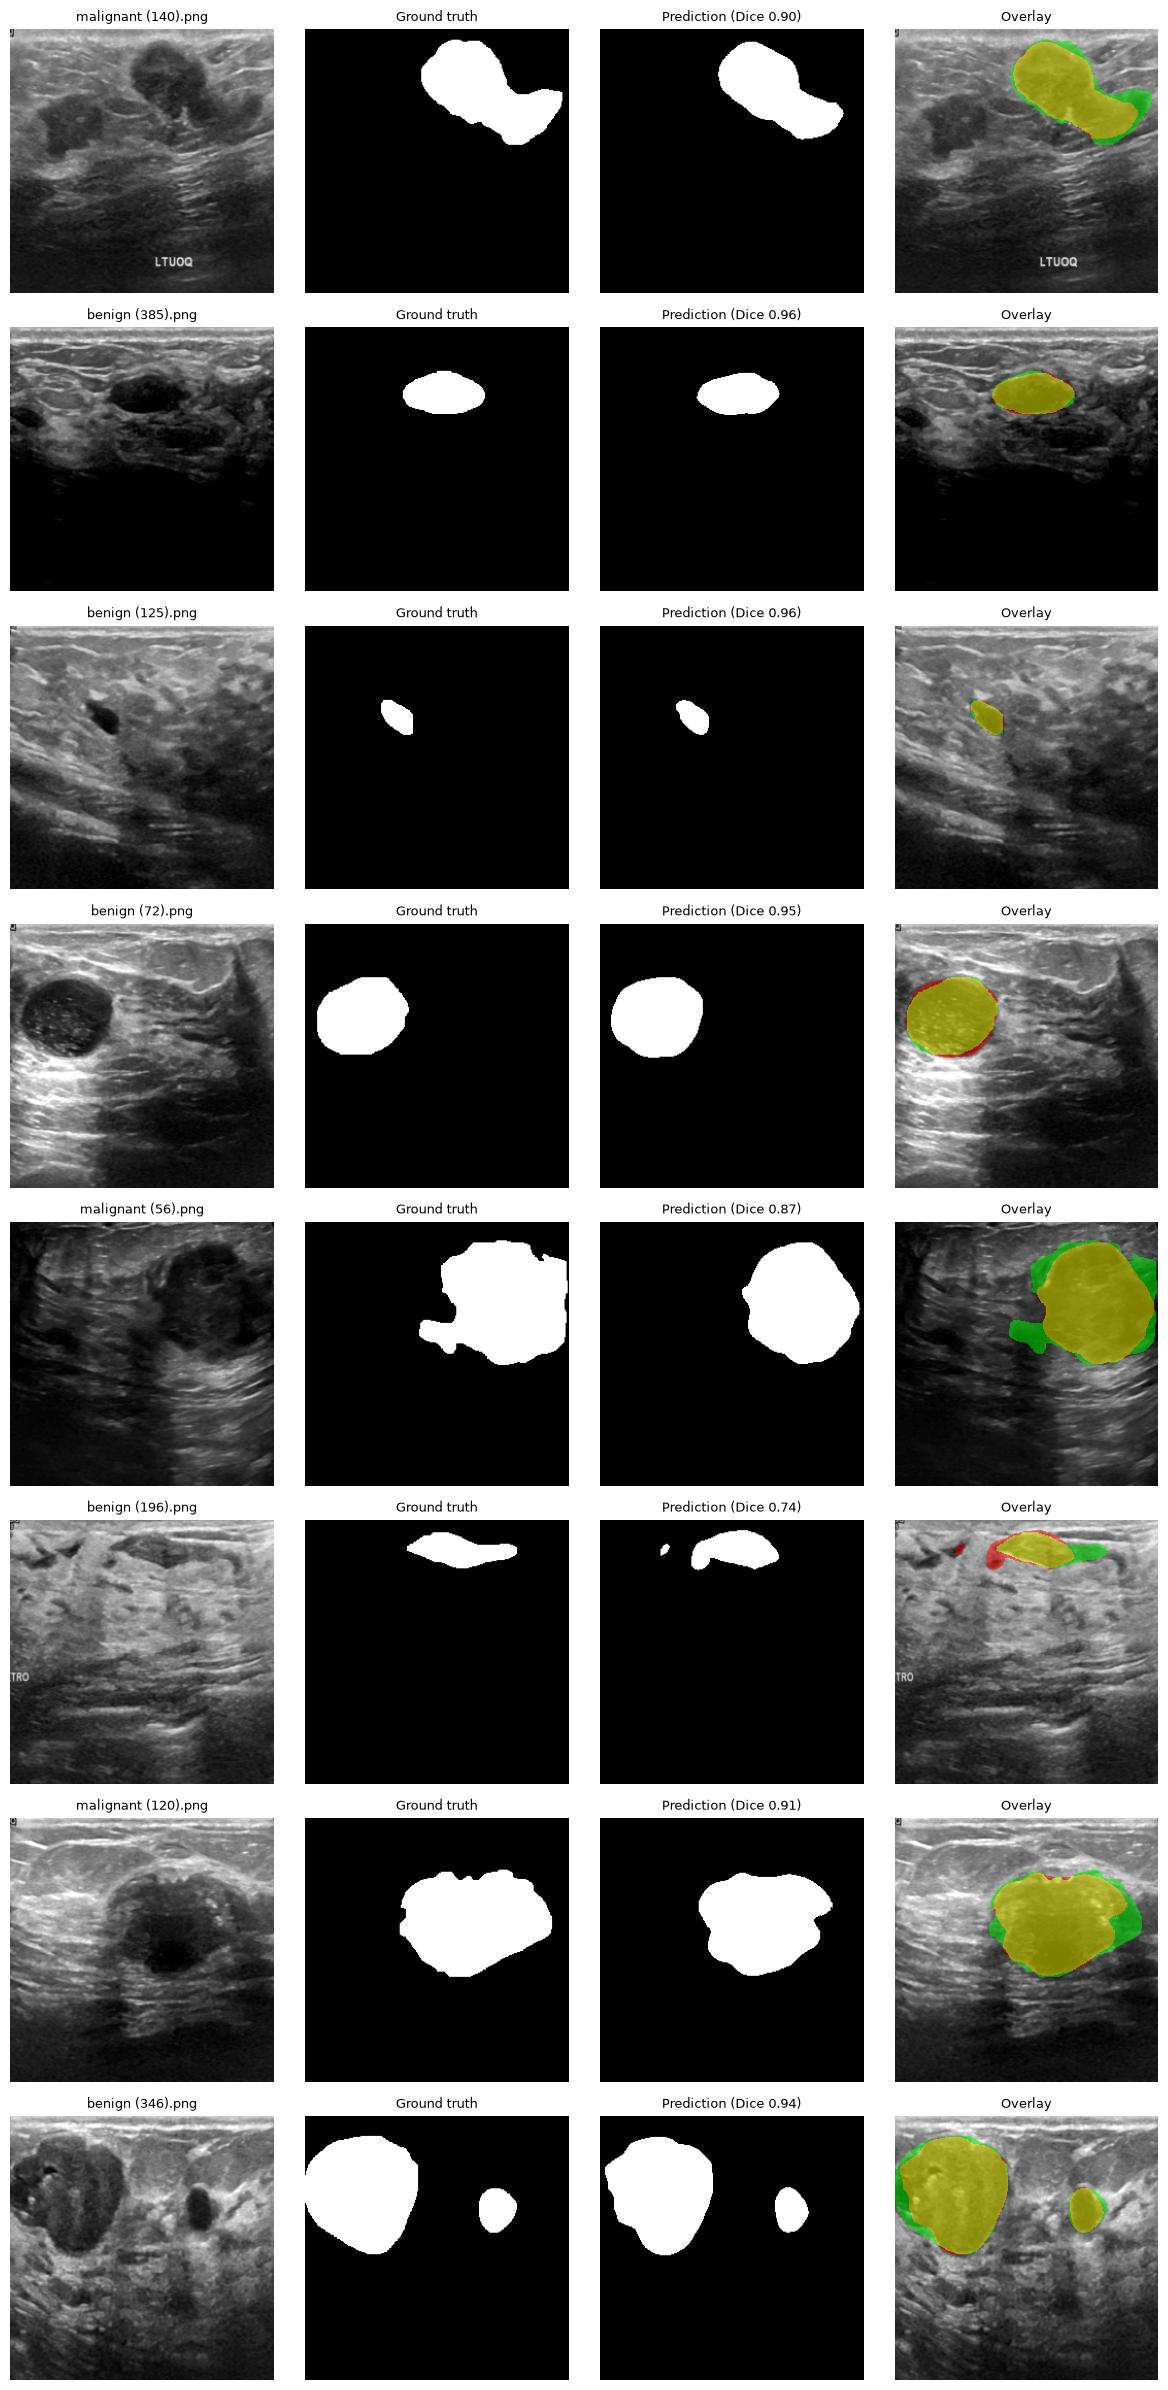

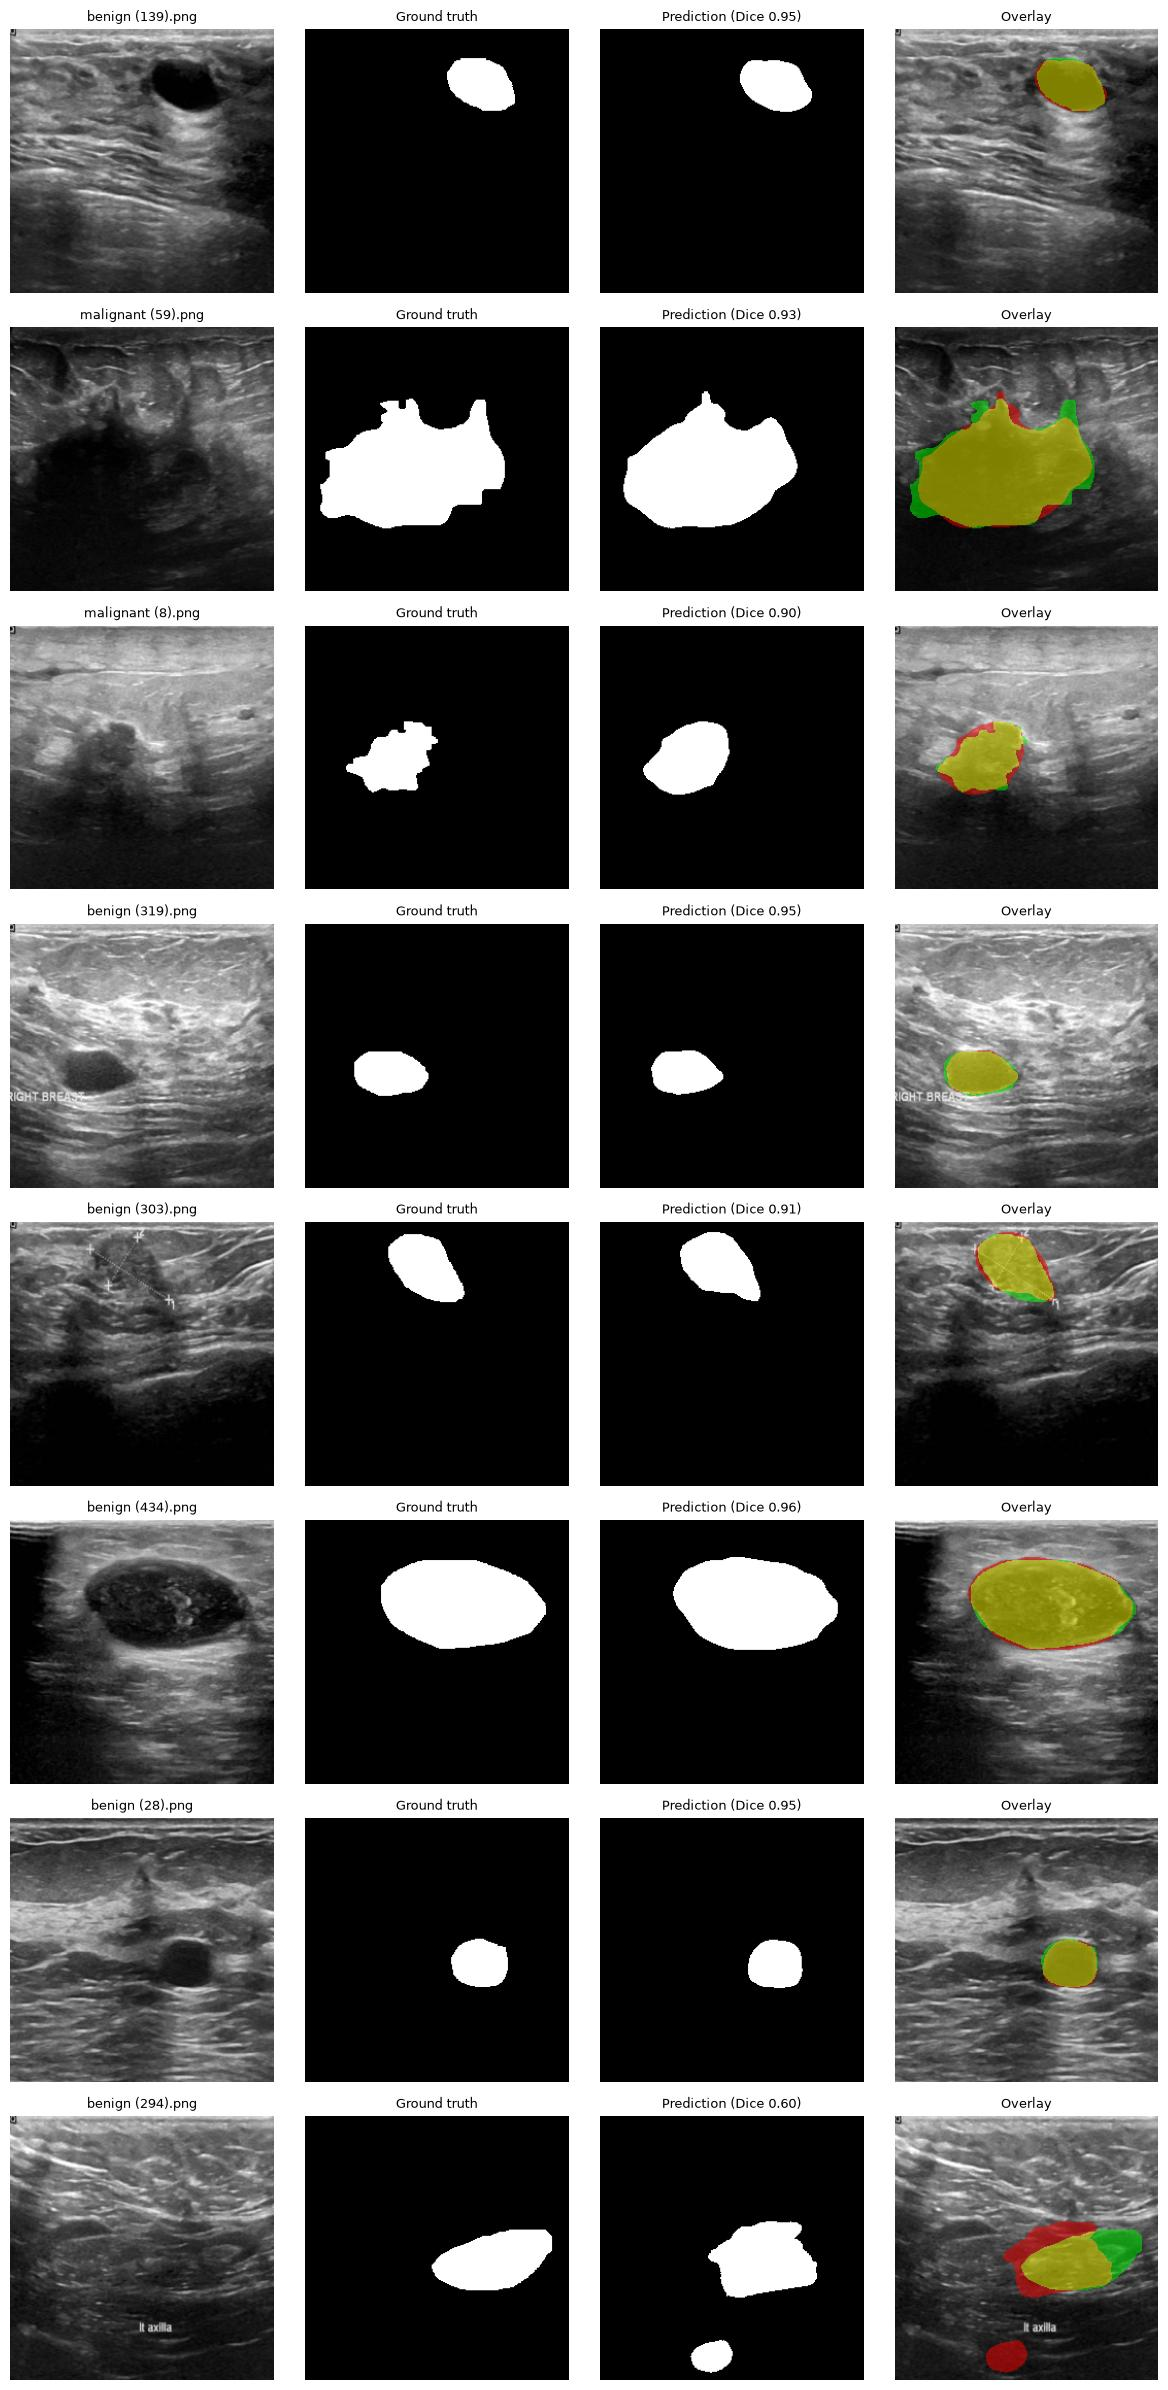

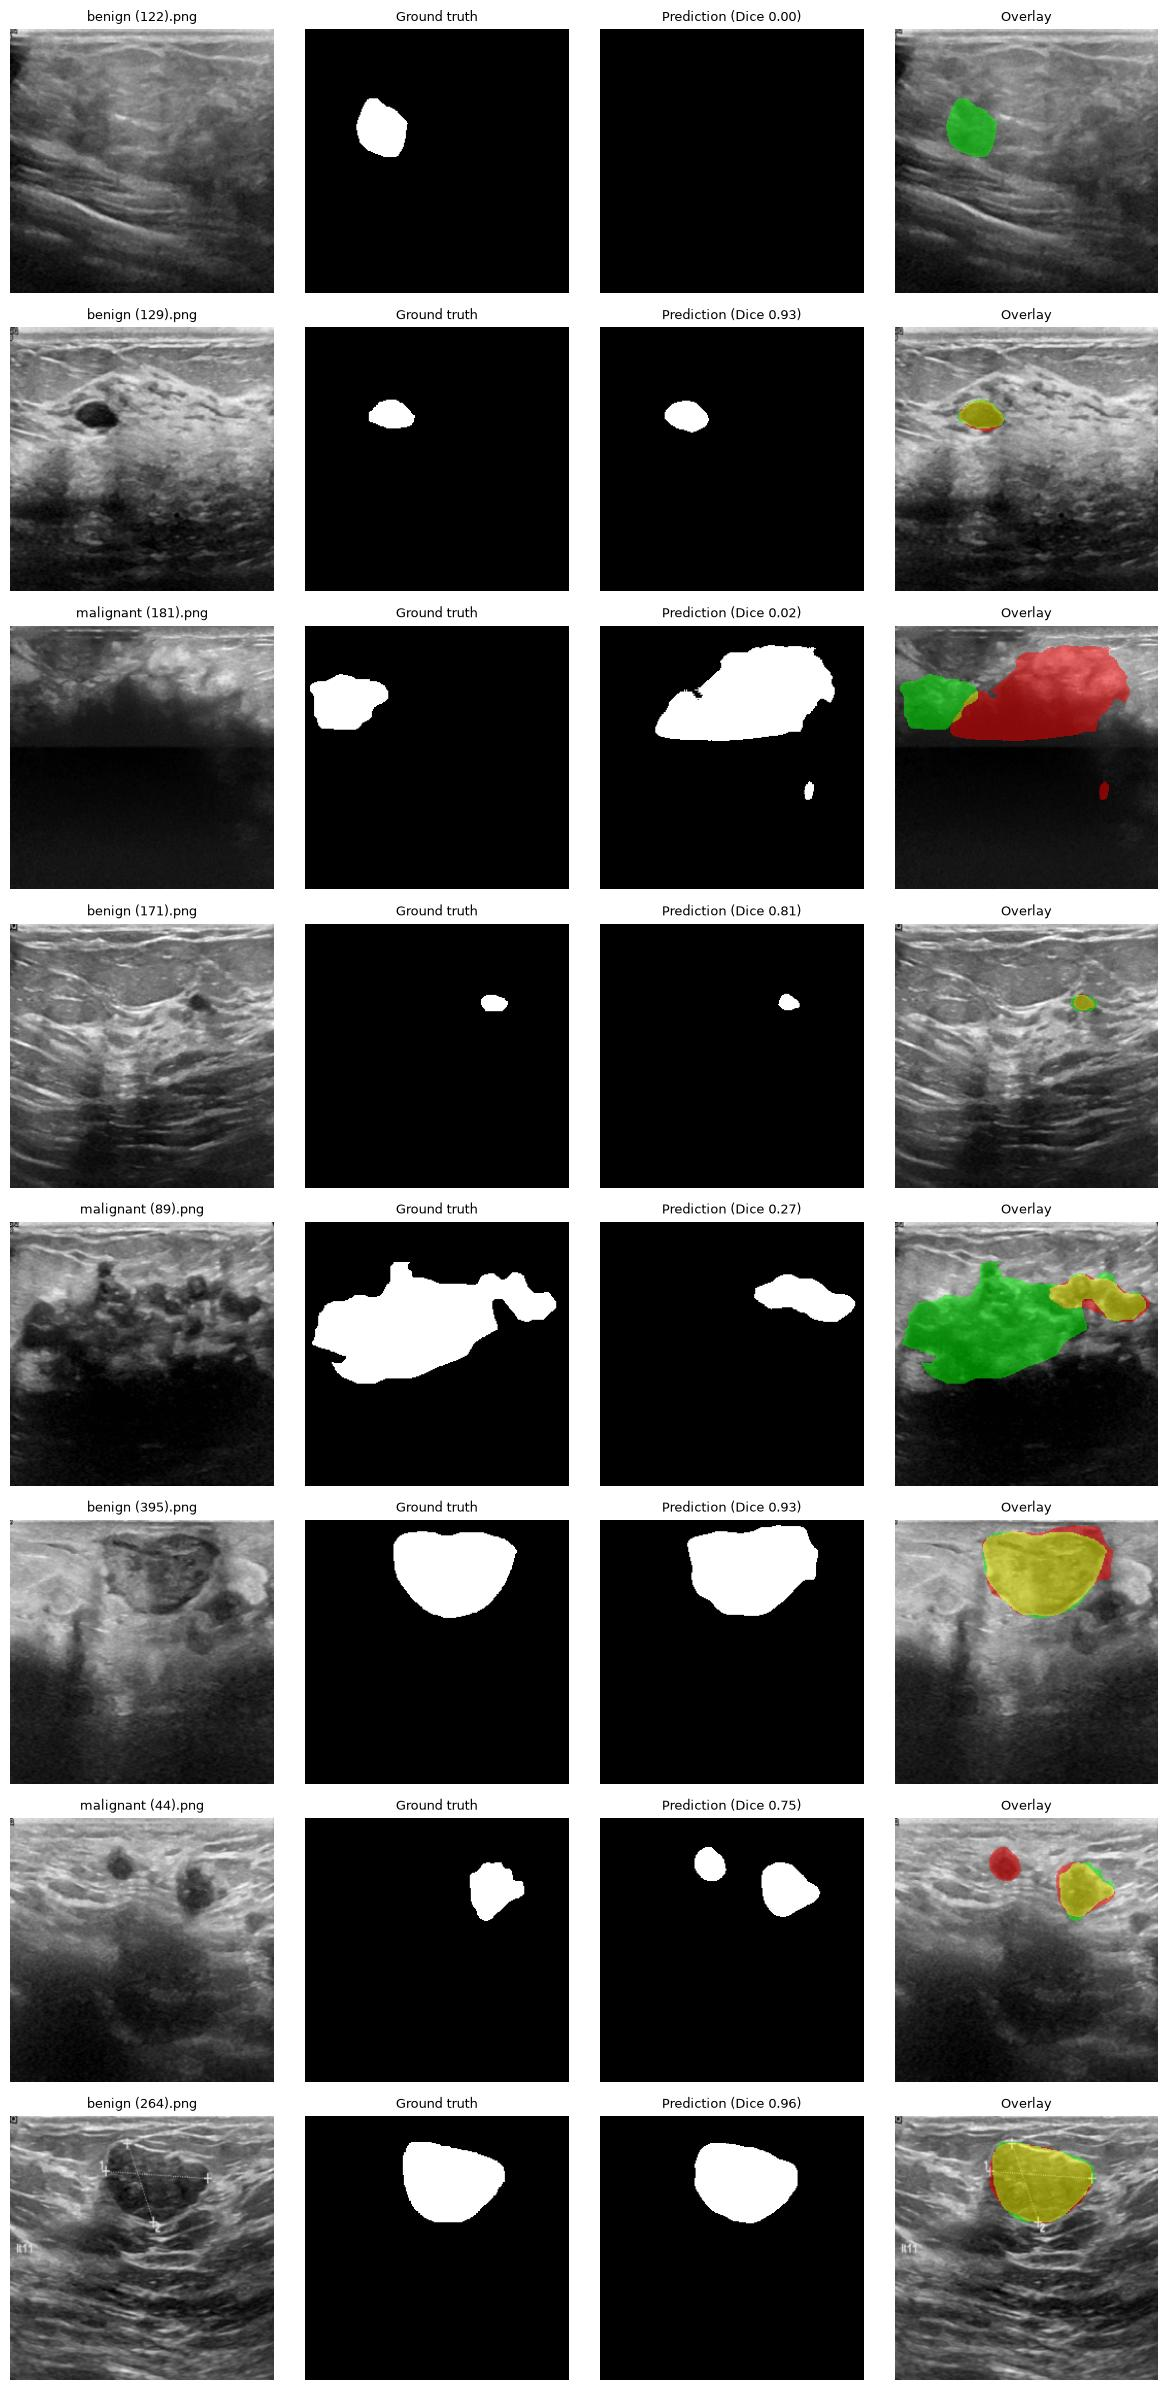

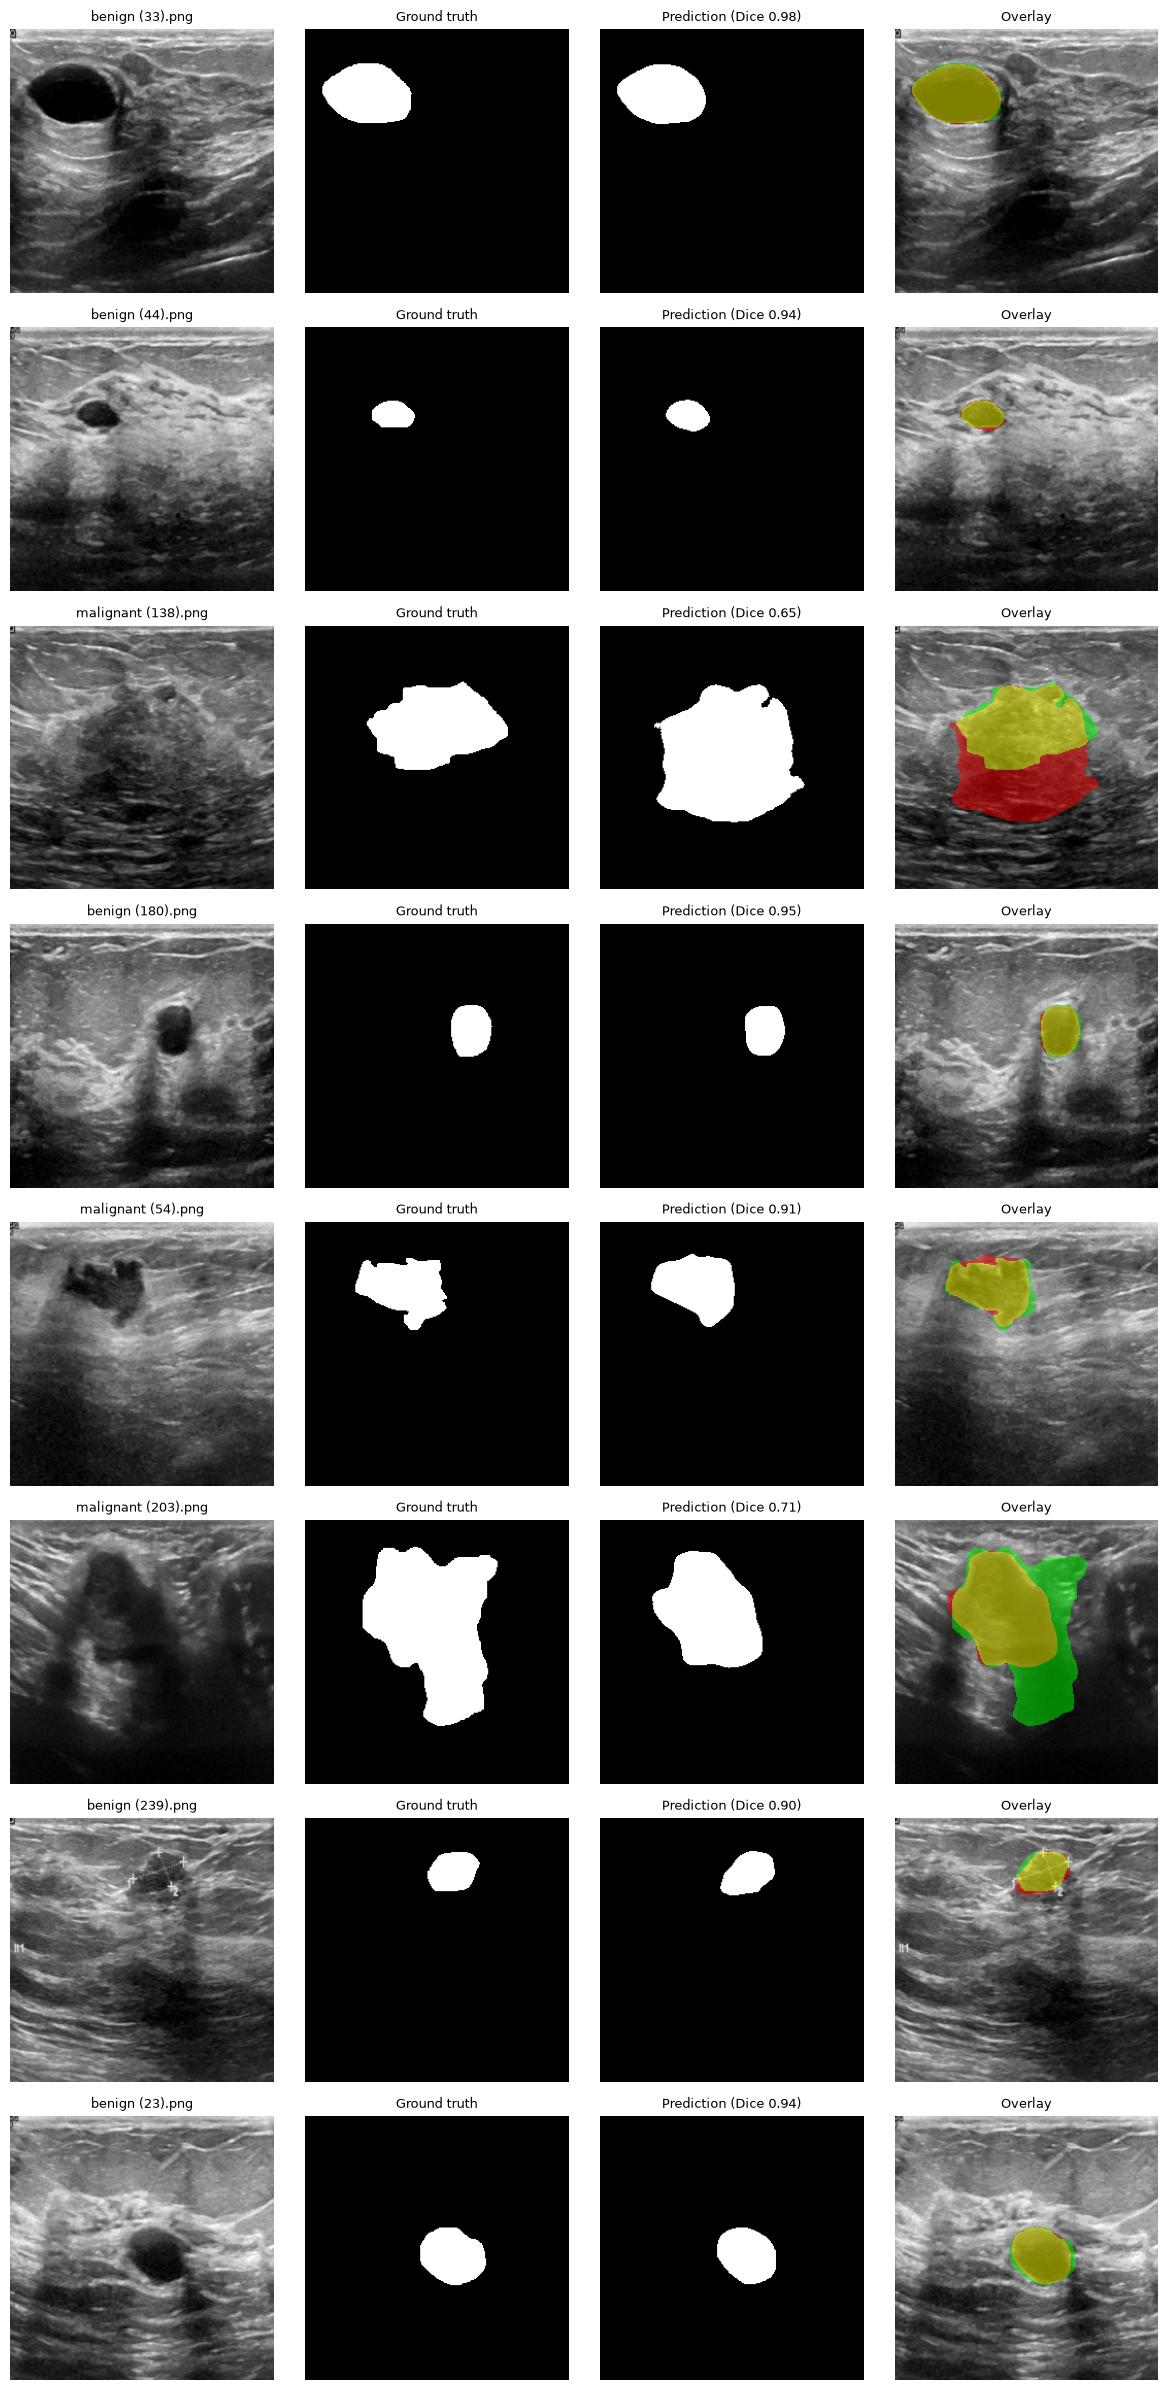

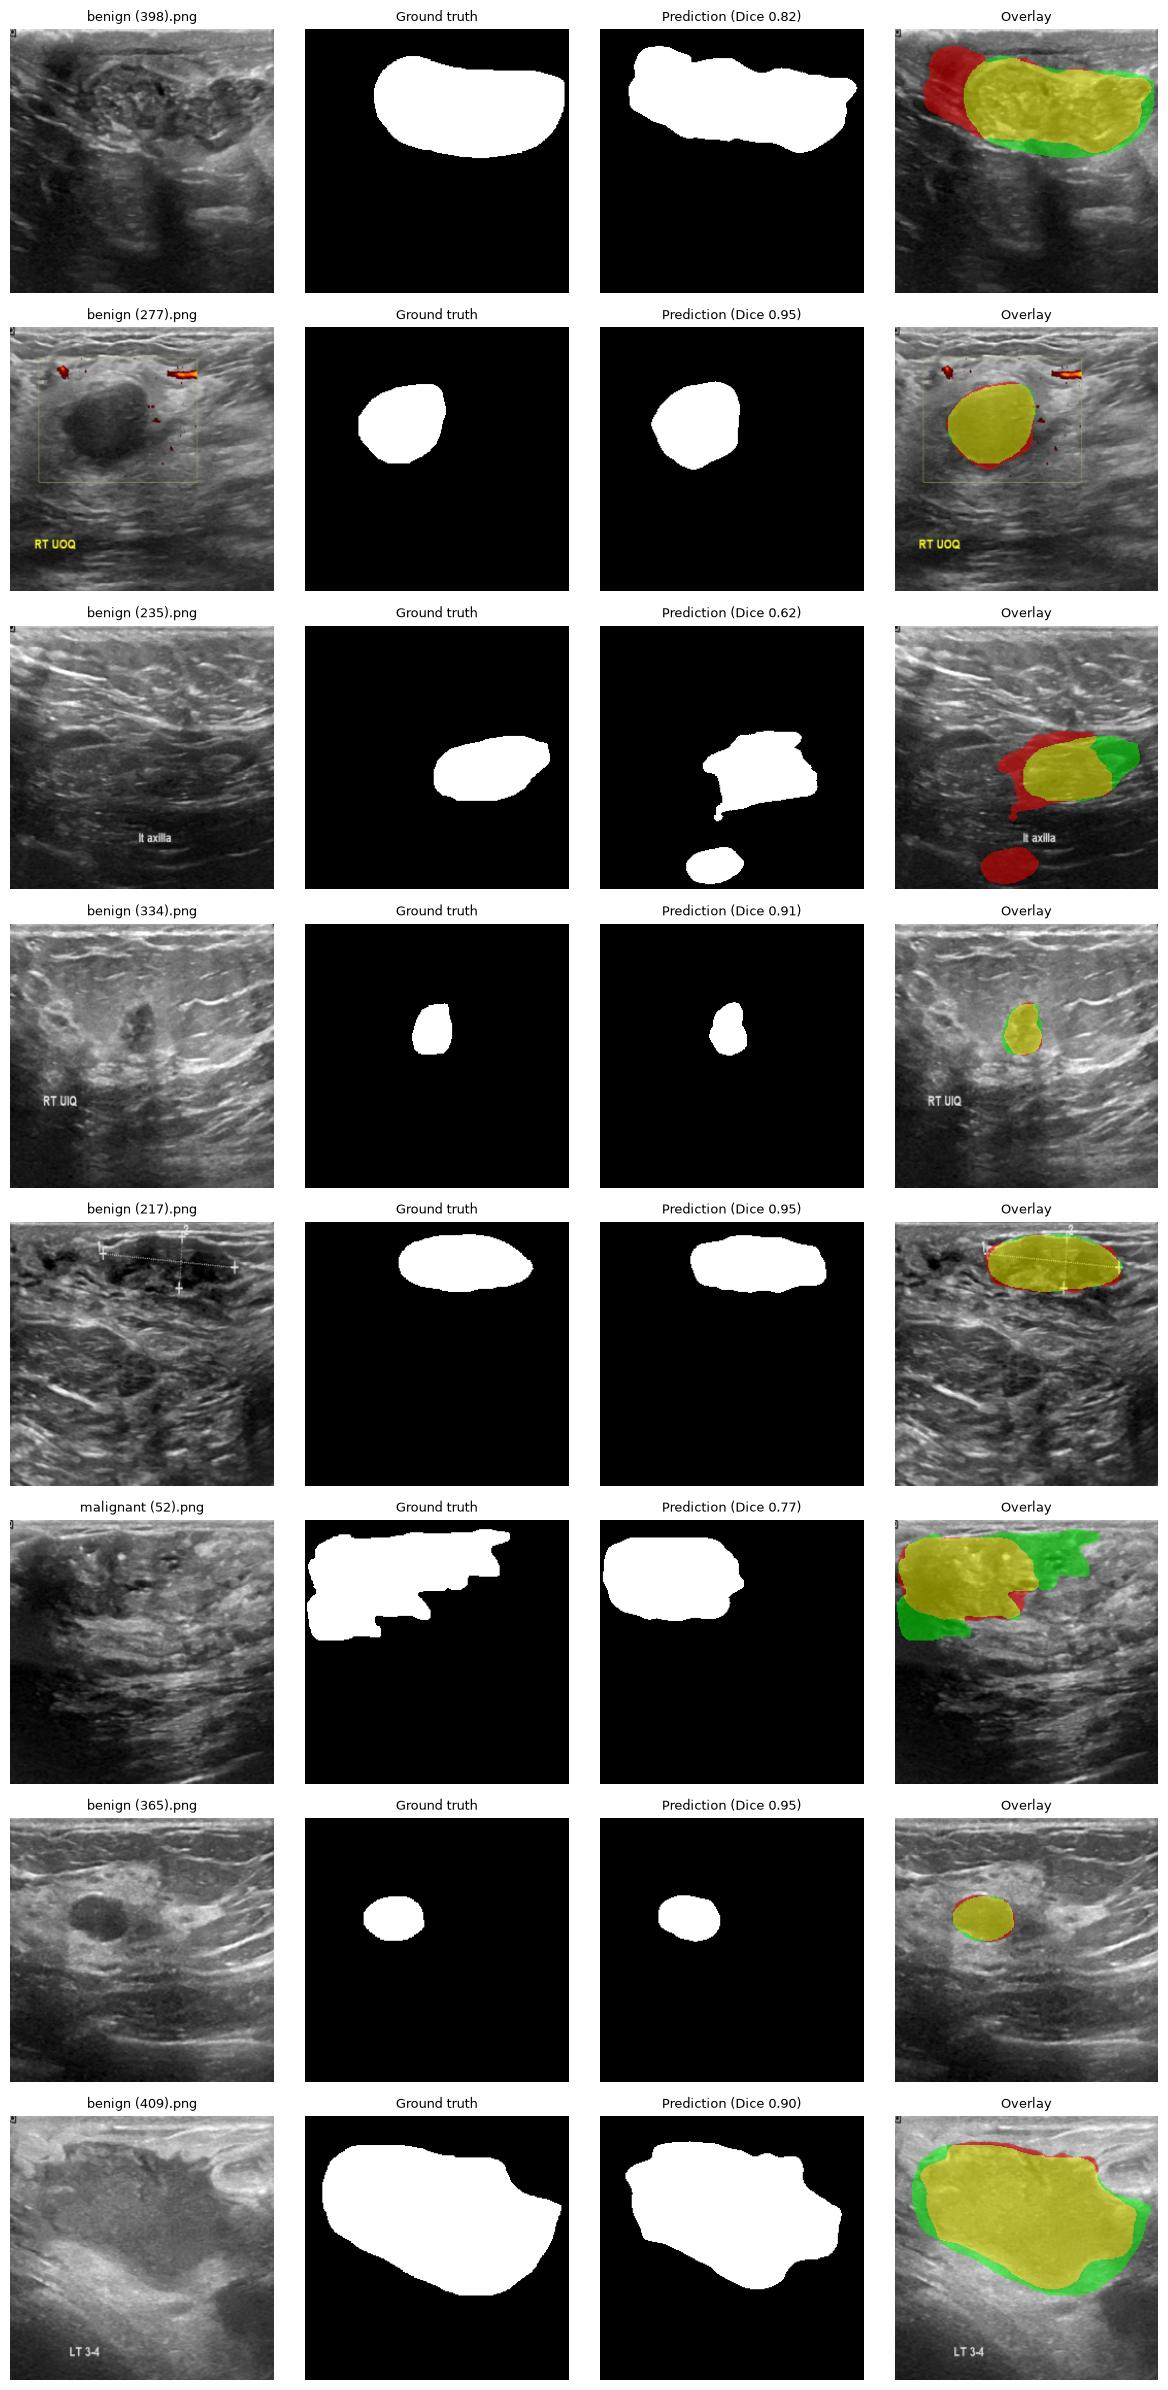

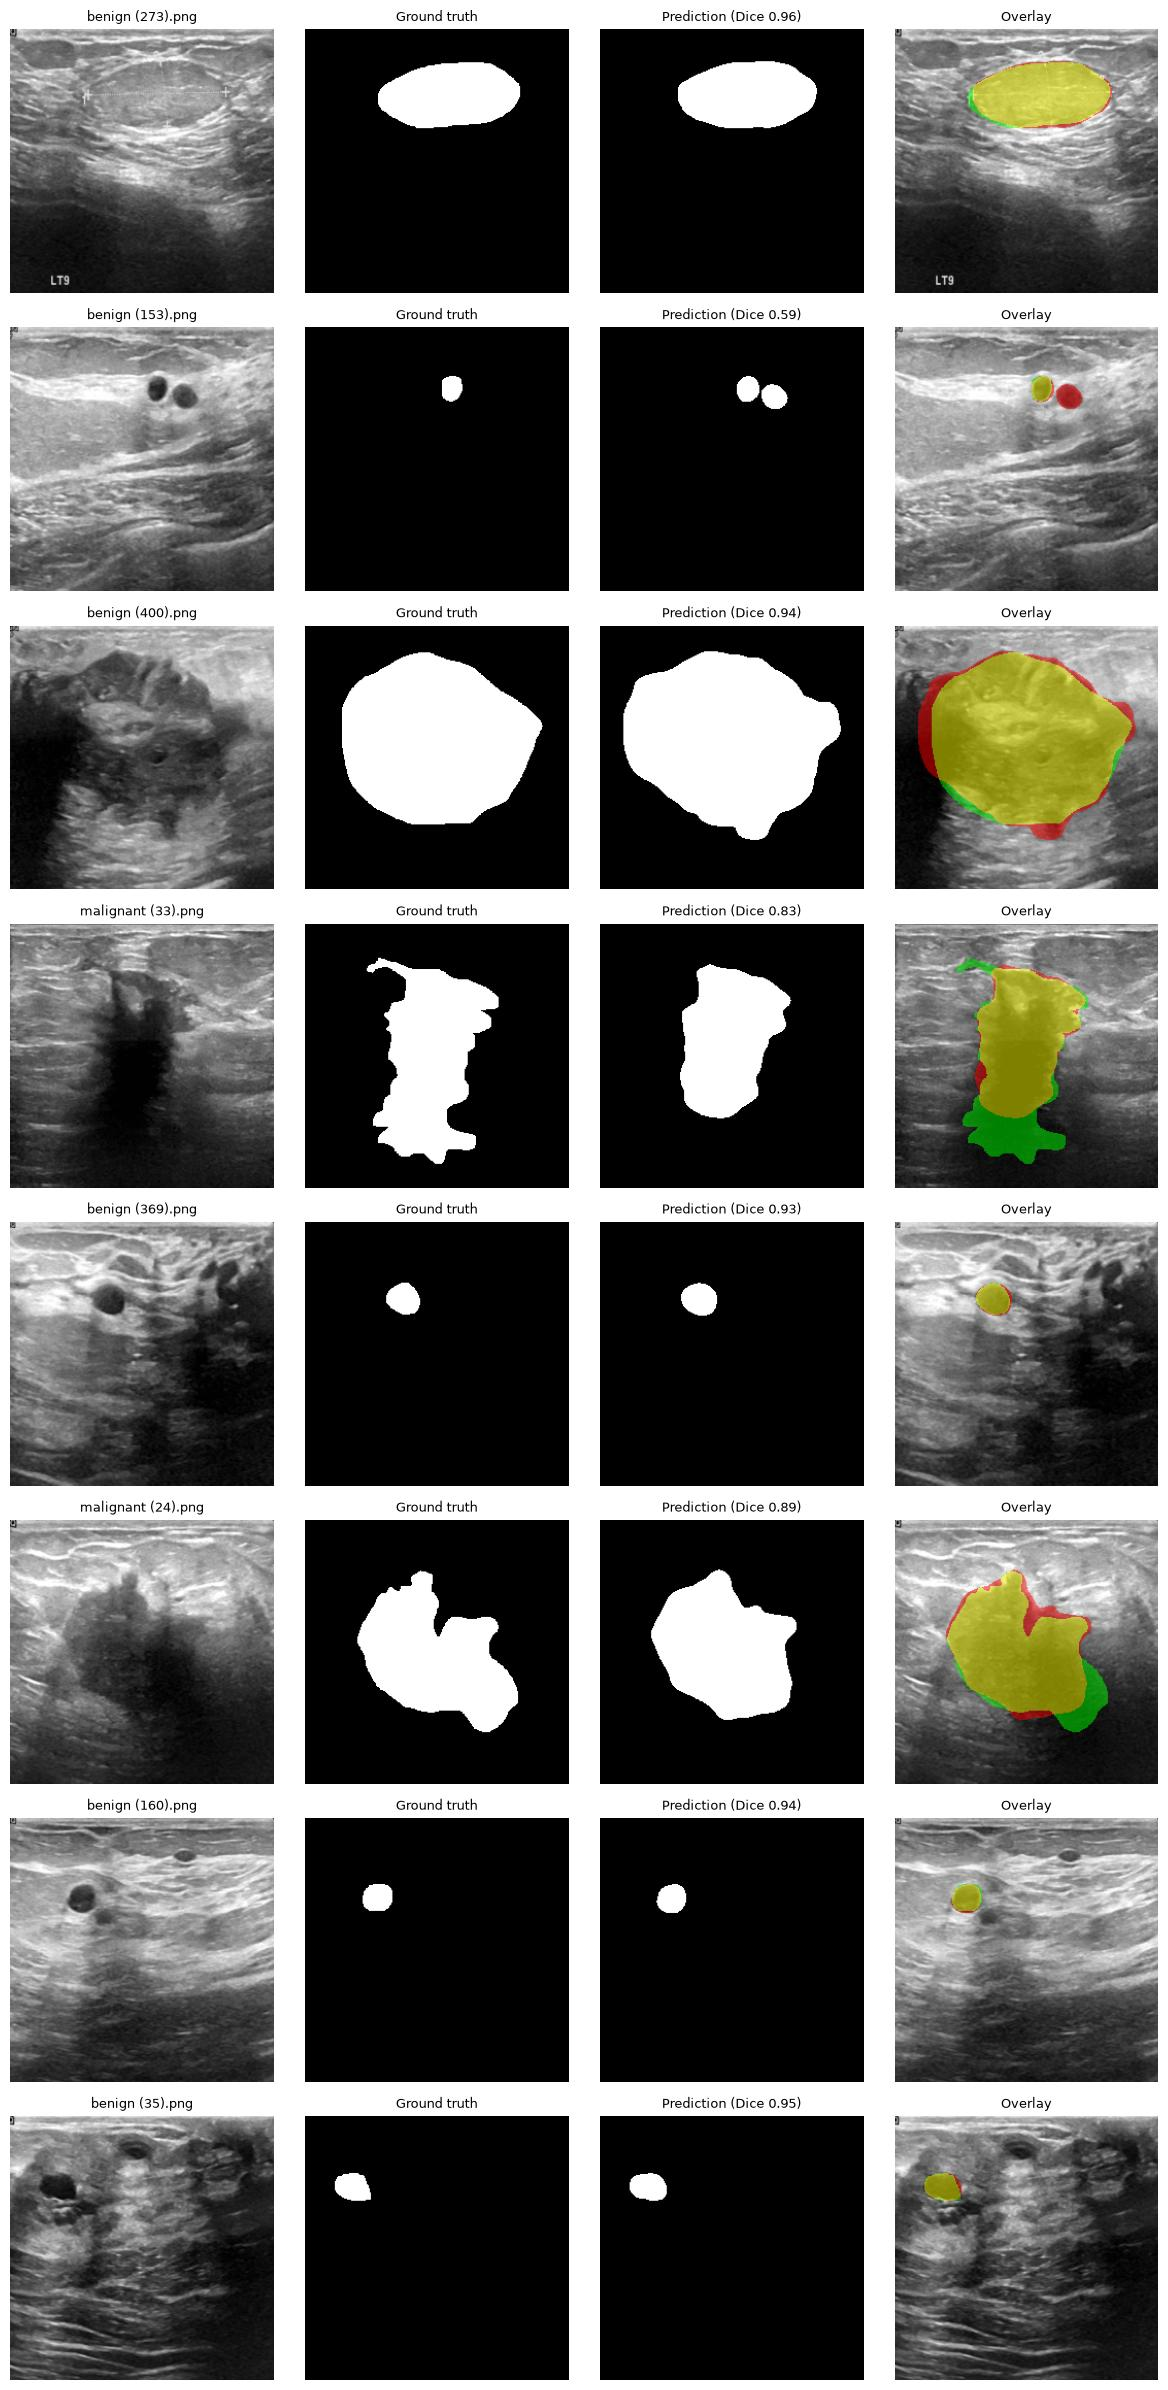

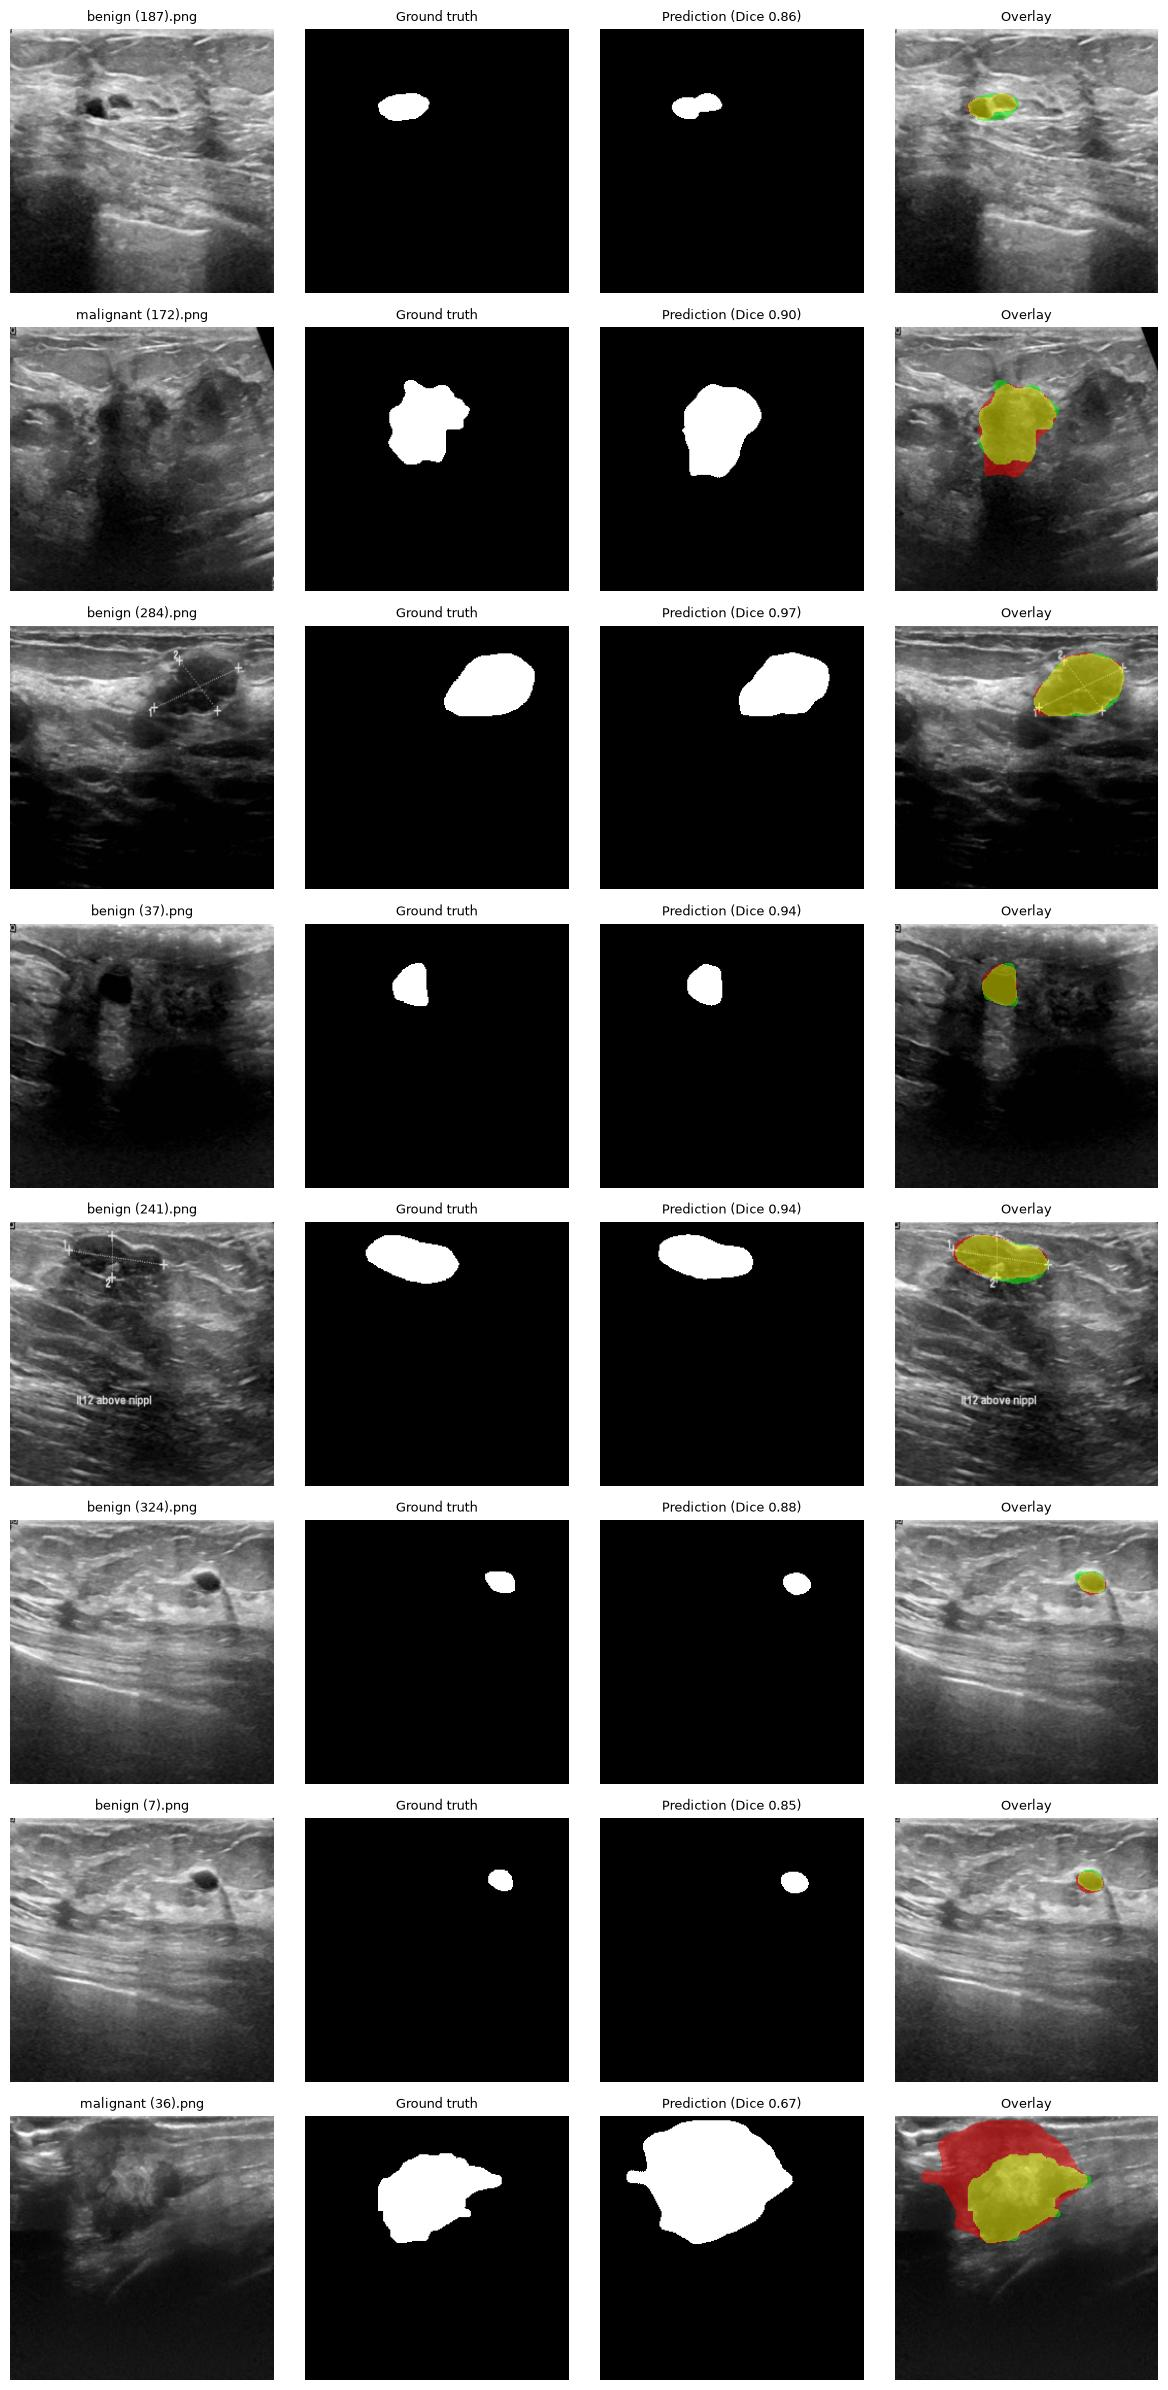

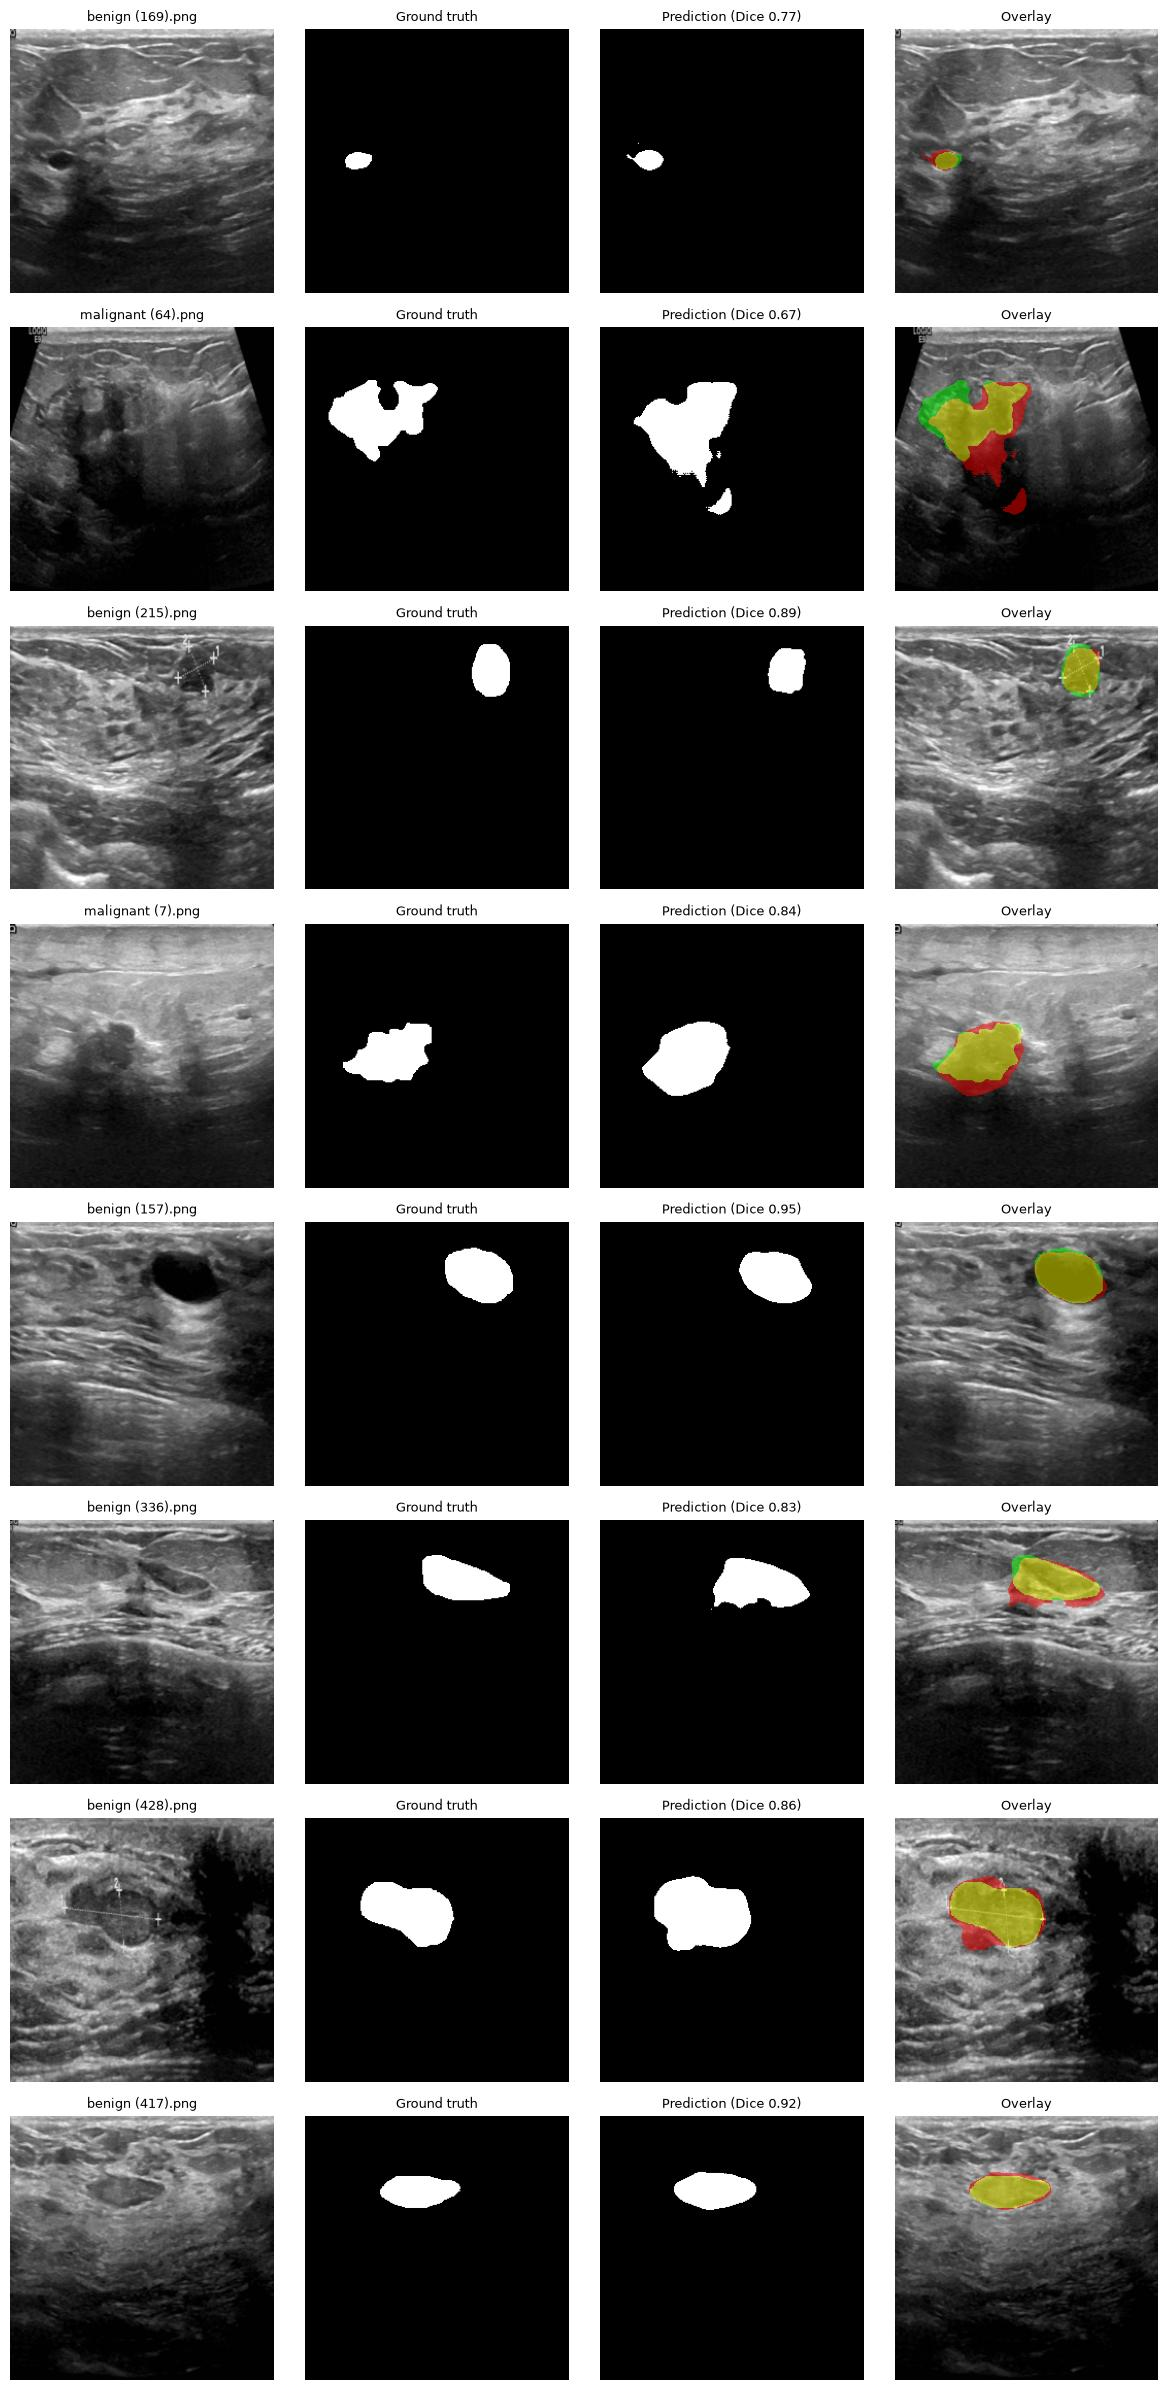

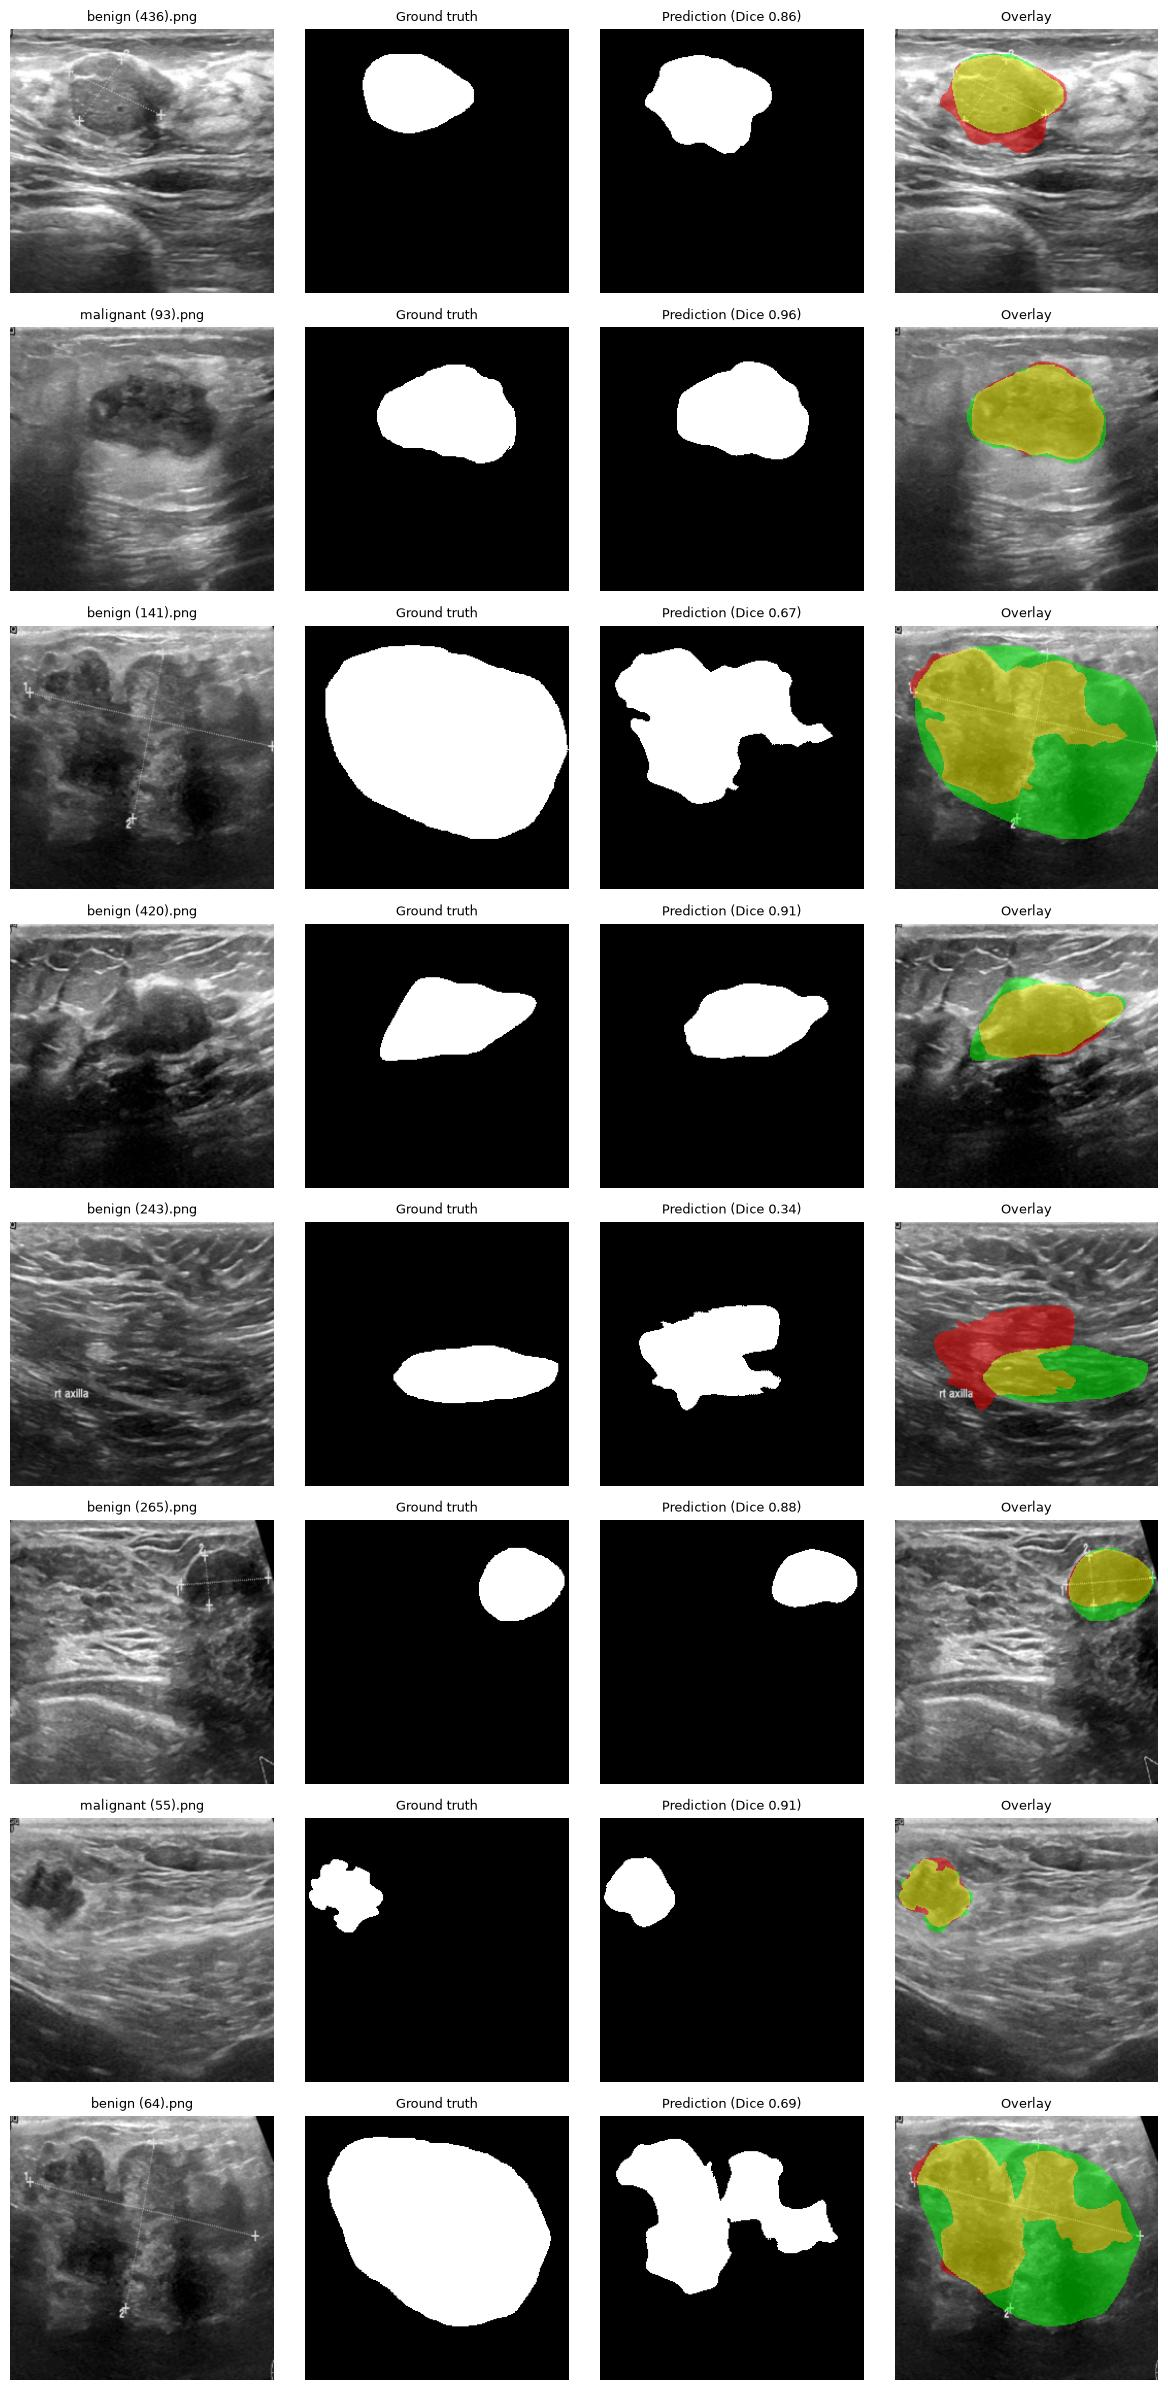

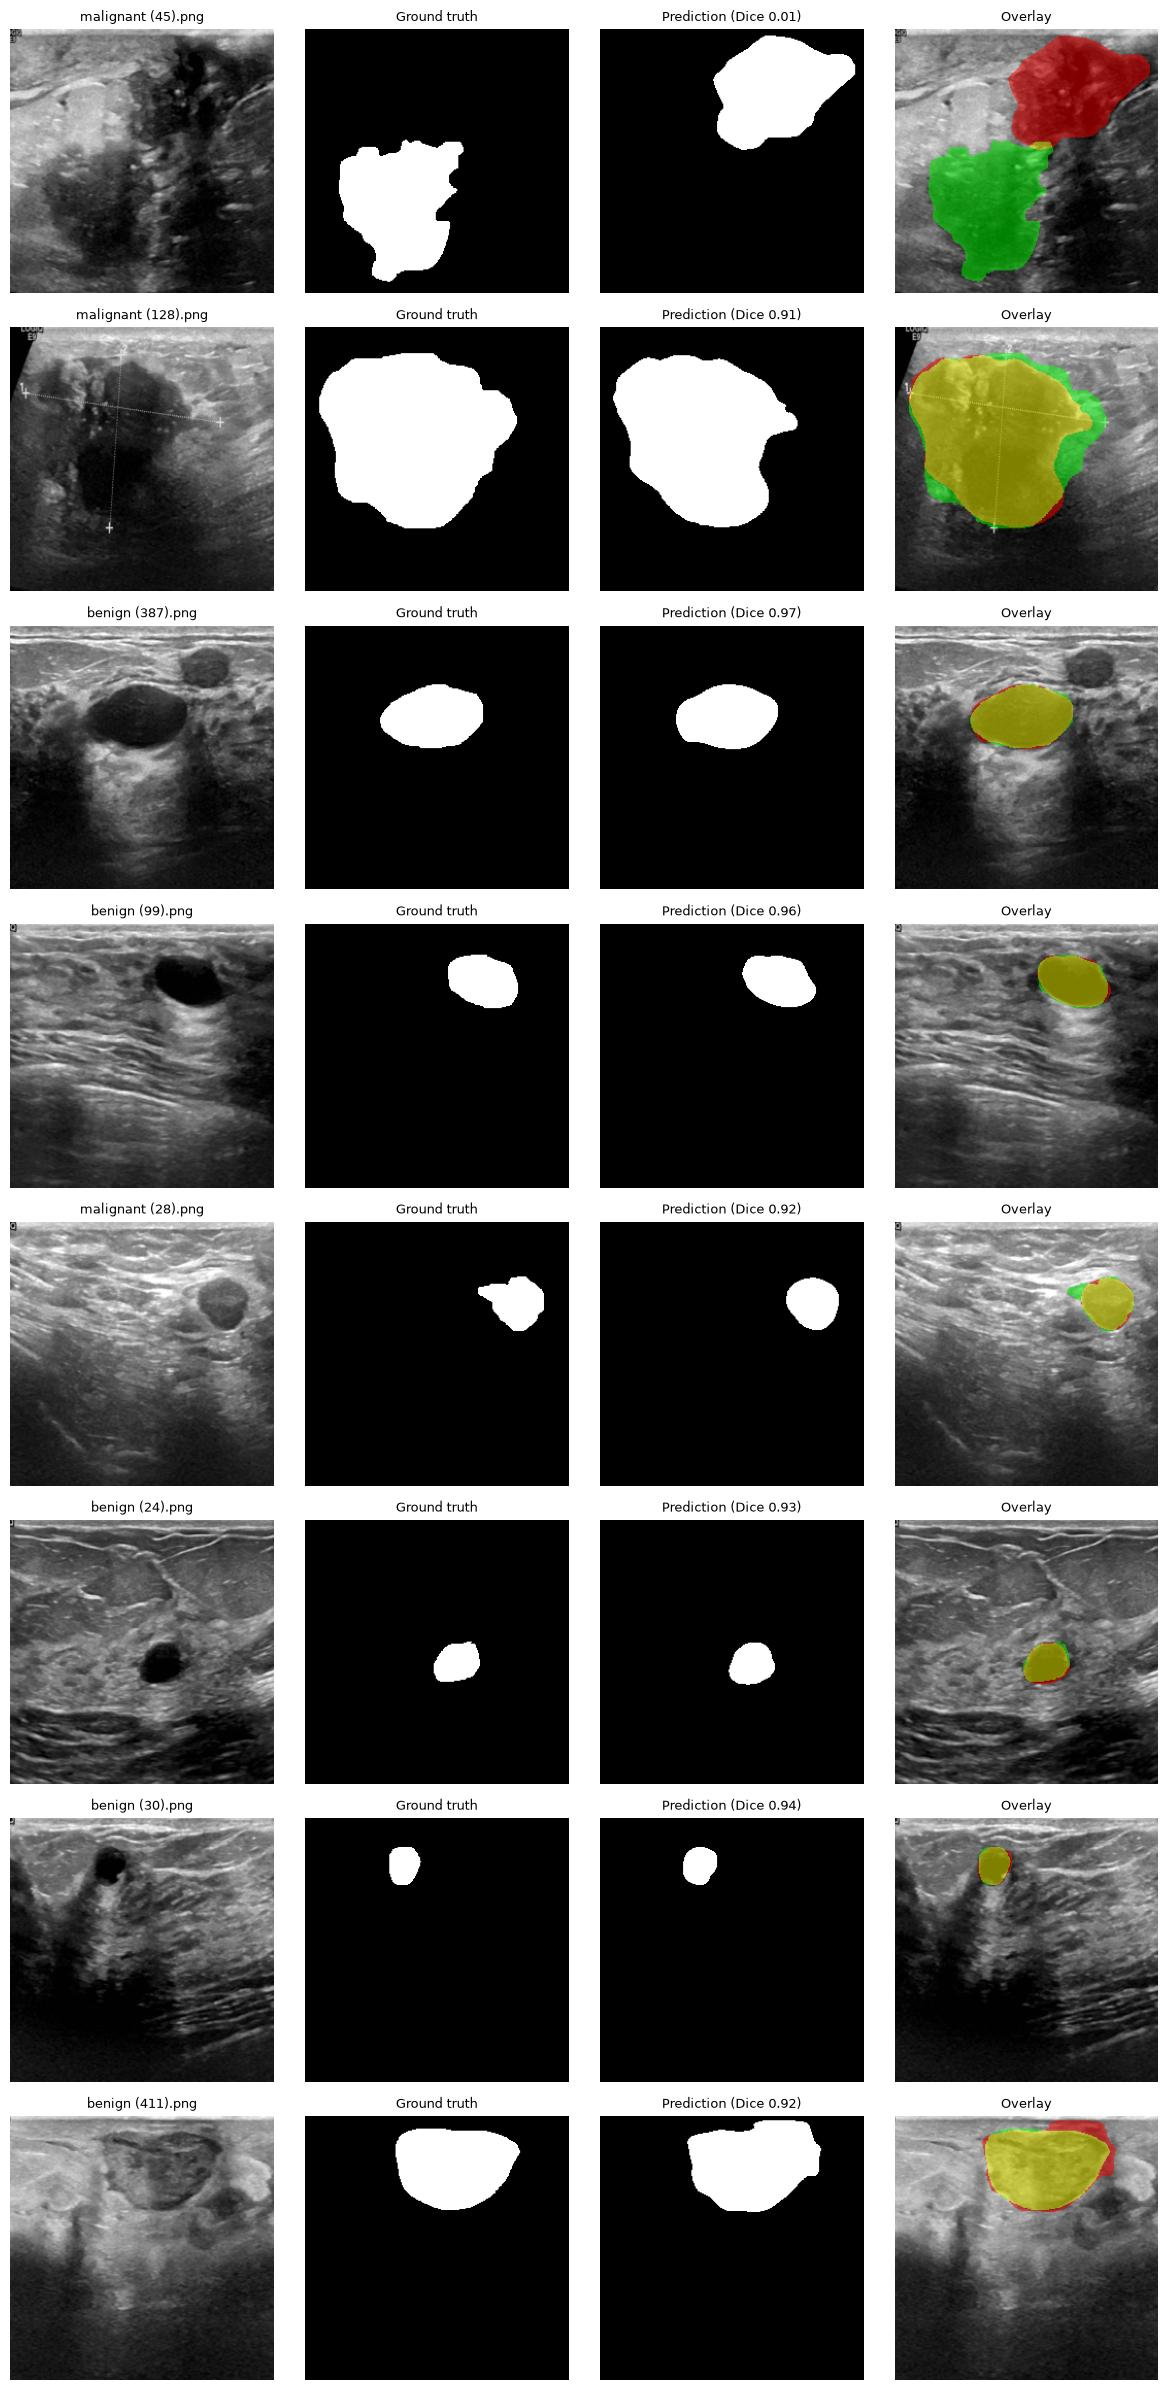

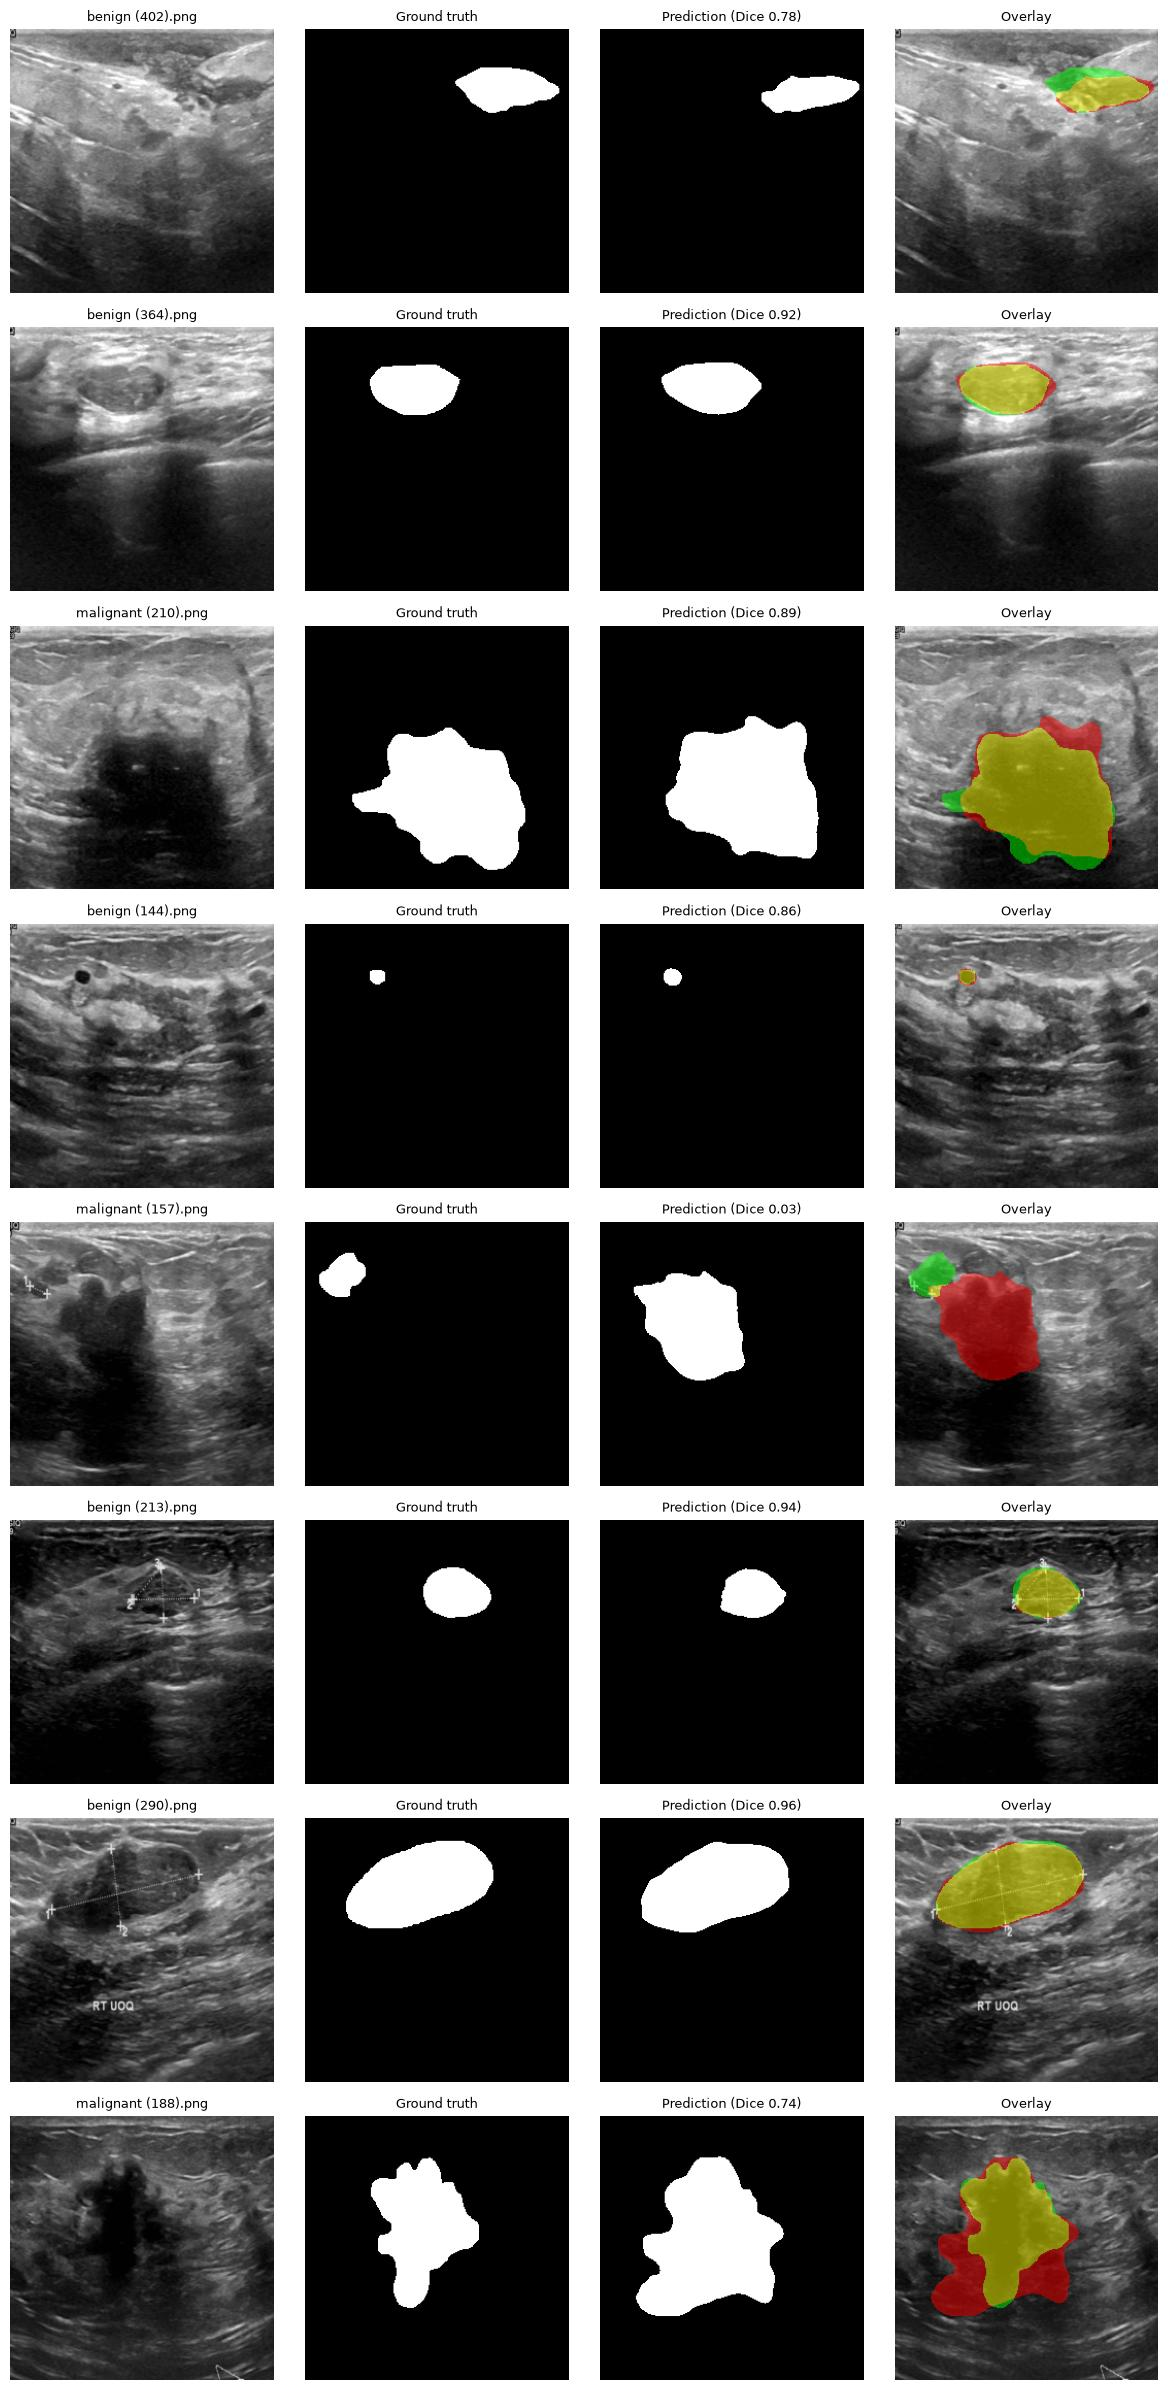

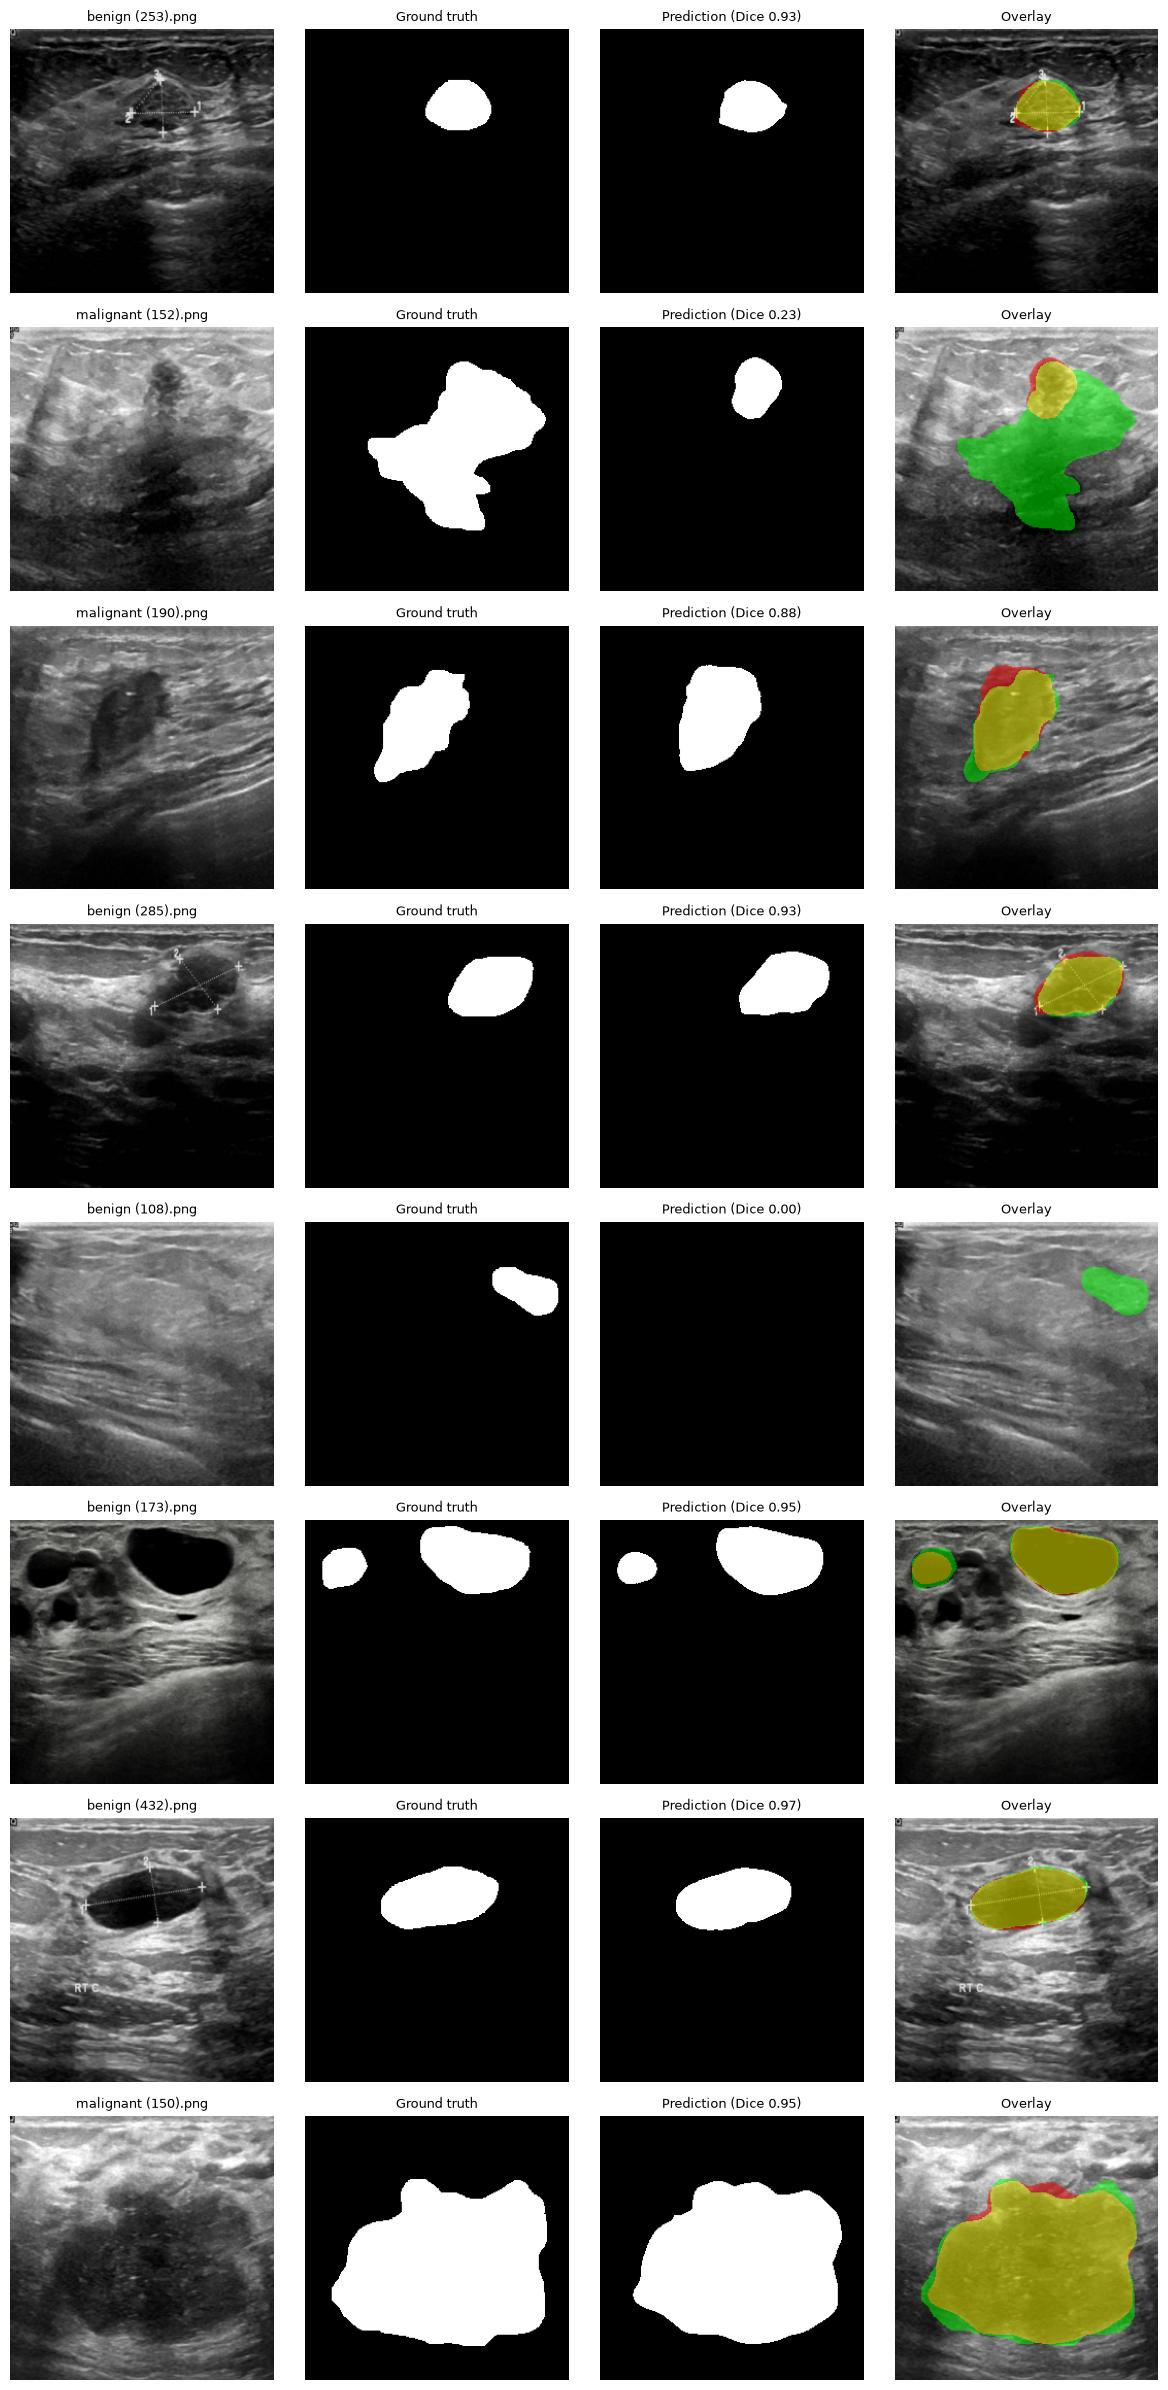

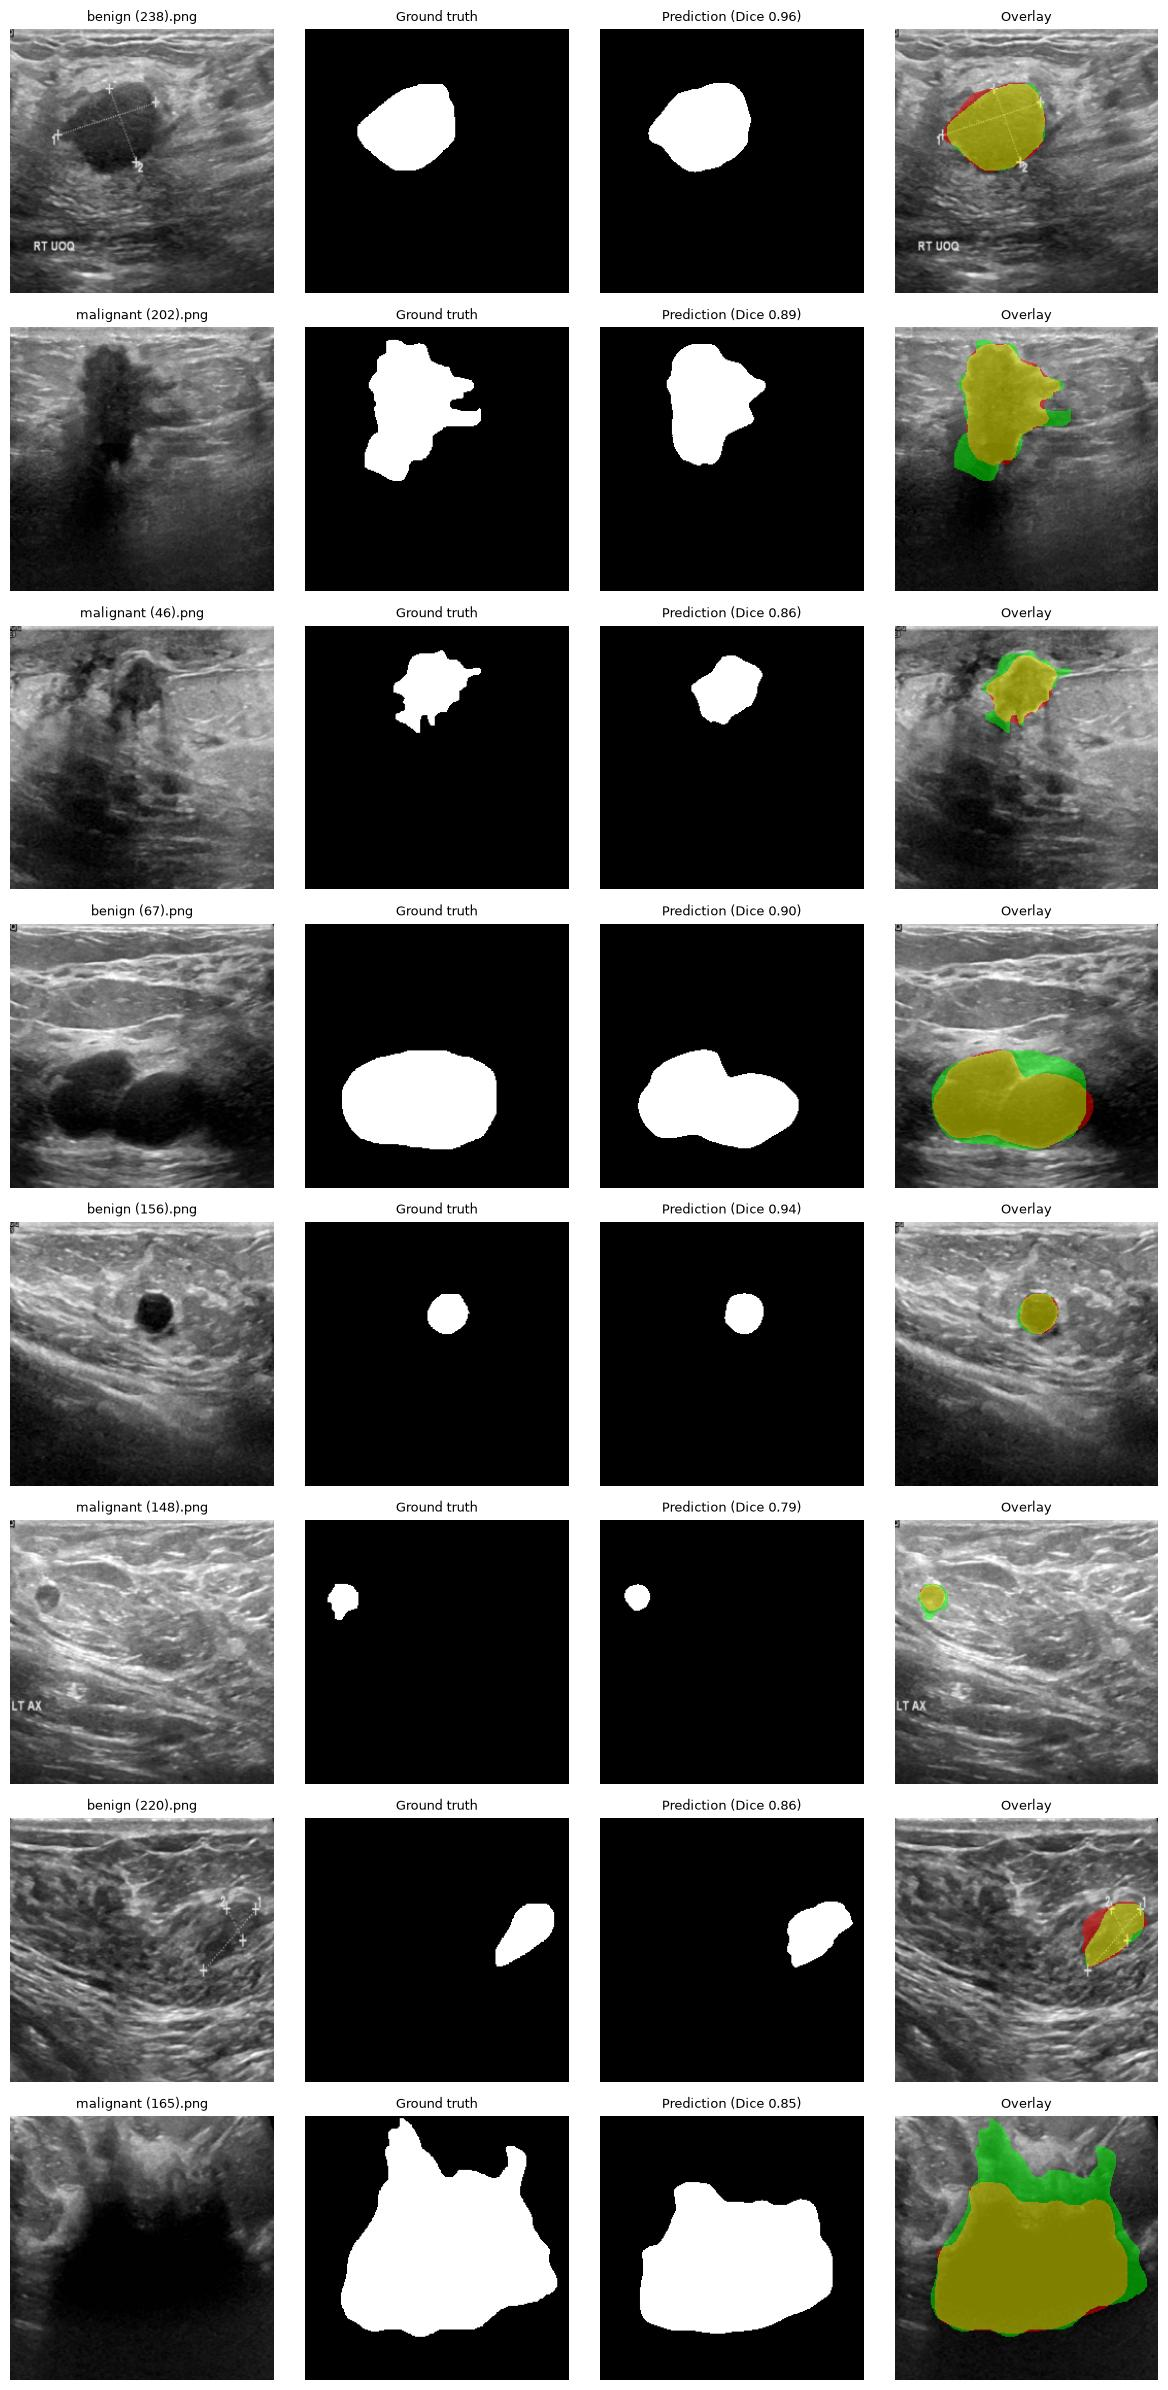

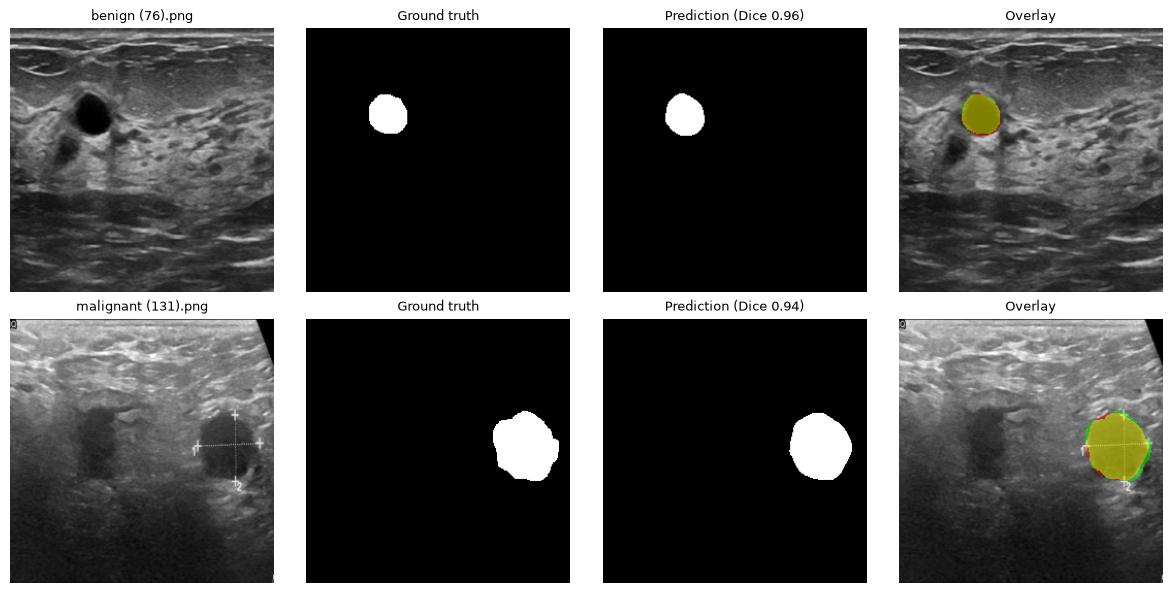

In [10]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight"}

VIS_DIR = RUN_DIR / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

PER_PAGE = 8   # images per figure, keeps every panel readable

# Display all test images: image | ground truth | prediction | error overlay.
for start in range(0, len(test_names), PER_PAGE):
    evaluate.show_results(
        img_dir=IMG_DIR,
        gt_dir=GT_DIR,
        pred_dir=PRED_DIR,
        names=test_names,
        start=start,
        count=PER_PAGE,
        save_path=VIS_DIR / f"vis_{start:03d}.png",
    )

## 12. Supplementary statistics

The mean Dice hides the difference between good and failed cases, and
the HD95 mean above excludes images where HD95 is undefined (the
prediction is empty). To make the comparison between models fair, we
also report the median, the number of failed cases, and an HD95 variant
in which undefined values are replaced by the image diagonal
(256 × √2 ≈ 362 px), the largest possible distance. This variant
penalizes missed tumors instead of ignoring them.

In [11]:
DIAGONAL = 256 * np.sqrt(2)   # largest possible distance in a 256 x 256 image

n = len(metrics_df)
hd95_penalized = metrics_df["hd95"].fillna(DIAGONAL)

print(f"Median Dice: {metrics_df['dice'].median():.4f}")
print(f"Median IoU : {metrics_df['iou'].median():.4f}")
print(f"Images with Dice = 0   : {(metrics_df['dice'] == 0).sum()} / {n}")
print(f"Images with Dice < 0.5 : {(metrics_df['dice'] < 0.5).sum()} / {n}")
print(f"Images with Dice >= 0.8: {(metrics_df['dice'] >= 0.8).sum()} / {n}")
print(f"HD95 (excluding undefined): {metrics_df['hd95'].mean():.2f} px "
      f"({metrics_df['hd95'].isna().sum()} excluded)")
print(f"HD95 (undefined set to {DIAGONAL:.0f} px): {hd95_penalized.mean():.2f} px")

Median Dice: 0.9031
Median IoU : 0.8233
Images with Dice = 0   : 2 / 130
Images with Dice < 0.5 : 10 / 130
Images with Dice >= 0.8: 100 / 130
HD95 (excluding undefined): 20.92 px (2 excluded)
HD95 (undefined set to 362 px): 26.17 px


## 13. Error analysis

To describe the errors in a structured way, we assign each test image to
a category using the predicted and ground-truth tumor areas:

- **Missed tumor**: the prediction is empty but the ground truth is not.
- **Wrong location**: the prediction is not empty but does not overlap
  the ground truth at all (Dice = 0).
- **Over-segmentation**: the predicted area is more than 1.5 times the
  ground-truth area.
- **Under-segmentation**: the predicted area is less than 0.5 times the
  ground-truth area.
- **Inaccurate boundary**: the areas are similar but Dice is below 0.8.
- **Good**: Dice is at least 0.8.

These thresholds are simple rules chosen for description only; they are
not used for training or model selection. If a ground-truth mask is
empty (no tumor), the image is labeled "No tumor in ground truth".

In [12]:
def categorize(row):
    """Assign one error category from areas and Dice (rules in the text above)."""
    if row["gt_area"] == 0:
        return "No tumor in ground truth"
    if row["pred_area"] == 0:
        return "Missed tumor"
    if row["dice"] == 0:
        return "Wrong location"
    if row["dice"] >= 0.8:
        return "Good"
    ratio = row["pred_area"] / row["gt_area"]
    if ratio > 1.5:
        return "Over-segmentation"
    if ratio < 0.5:
        return "Under-segmentation"
    return "Inaccurate boundary"


# Collect predicted/ground-truth areas and error pixels for every test image.
areas = []
for name in test_names:
    pred = evaluate.load_mask(PRED_DIR / name)
    gt = evaluate.load_mask(GT_DIR / name)
    areas.append({
        "name": name,
        "pred_area": int(pred.sum()),
        "gt_area": int(gt.sum()),
        "false_positive_px": int((pred & ~gt).sum()),   # red in the overlay
        "false_negative_px": int((gt & ~pred).sum()),   # green in the overlay
    })

analysis_df = metrics_df.merge(pd.DataFrame(areas), on="name")
analysis_df["category"] = analysis_df.apply(categorize, axis=1)
analysis_df.to_csv(RUN_DIR / "error_analysis.csv", index=False)

# Number of images per category and their mean Dice.
display(
    analysis_df.groupby("category")["dice"]
    .agg(count="count", mean_dice="mean")
    .round(4)
    .sort_values("count", ascending=False)
)

# Image names in each failure category, to find them quickly in the figures.
for category in ["Missed tumor", "Wrong location", "Over-segmentation",
                 "Under-segmentation", "Inaccurate boundary"]:
    names_in_category = analysis_df.loc[analysis_df["category"] == category, "name"]
    print(f"\n{category} ({len(names_in_category)}):")
    print(", ".join(names_in_category) if len(names_in_category) else "none")

# Does the model do worse on small tumors? Mean Dice by ground-truth size.
analysis_df["size_group"] = pd.qcut(
    analysis_df["gt_area"], 3, labels=["small", "medium", "large"]
)
display(
    analysis_df.groupby("size_group", observed=True)["dice"]
    .agg(["count", "mean"]).round(4)
)

,count,mean_dice
category,,
Good,100,0.9167
Inaccurate boundary,16,0.6545
Over-segmentation,9,0.4917
Under-segmentation,3,0.2050
Missed tumor,2,0.0000



Missed tumor (2):
benign (122).png, benign (108).png

Wrong location (0):
none

Over-segmentation (9):
benign (219).png, benign (427).png, benign (344).png, malignant (181).png, malignant (138).png, benign (153).png, malignant (36).png, malignant (157).png, malignant (188).png

Under-segmentation (3):
benign (199).png, malignant (89).png, malignant (152).png

Inaccurate boundary (16):
benign (14).png, malignant (62).png, benign (196).png, benign (294).png, malignant (44).png, malignant (203).png, benign (235).png, malignant (52).png, benign (169).png, malignant (64).png, benign (141).png, benign (243).png, benign (64).png, malignant (45).png, benign (402).png, malignant (148).png


,count,mean
size_group,,
small,44,0.8089
medium,43,0.8763
large,43,0.7887


## 14. Summary of the nnU-Net results

**Overall performance.** On the 130 test images, nnU-Net reaches a mean
Dice of 0.8245 ± 0.2204, a mean IoU of 0.7436 ± 0.2309 and a mean HD95
of 20.92 ± 29.78 px. Two images with an empty prediction have no defined
HD95 and are excluded from this mean; when they are counted as 362 px
(the image diagonal), the mean HD95 is 26.17 px. The median Dice (0.9031)
is clearly higher than the mean, so the average is lowered by a minority
of failed cases: 100 of 130 images (77%) reach Dice ≥ 0.8, 10 images (8%)
have Dice < 0.5, and 2 images (2%) have Dice = 0.

**Distribution of error types.** Using the rules in Section 13, 100 images
are segmented well (mean Dice 0.9167), 16 have an inaccurate boundary
(0.6545), 9 are over-segmented (0.4917), 3 are under-segmented (0.2050)
and 2 are missed tumors (0.0000). No image is labeled "wrong location".
Over-segmentation (9 images) is more frequent than under-segmentation
(3 images plus 2 missed tumors), so the model errs more often by
predicting too much tumor than too little. Note that the rules label an
image "wrong location" only when Dice is exactly 0, so images with an
almost complete failure but a Dice slightly above 0 are assigned to
another category.

**Missed tumors.** The only empty predictions are benign (122) and
benign (108), whose ground-truth tumors cover 2,074 and 2,025 pixels
(about 3% of the 256 × 256 image each). These images receive
Dice = IoU = 0 and have no defined HD95. In the overlays, the whole tumor
is a false negative. In both images the tumor is small (upper left in
benign (122), upper right in benign (108)) and the surrounding tissue has
a low-contrast, striped texture, so the tumor has almost the same gray
level as its surroundings and no clearly delineated border is visible.

**Near-complete failures.** Three images have a non-empty prediction that
almost does not overlap the ground truth: malignant (45) (Dice 0.0128,
HD95 128.51 px), malignant (181) (Dice 0.0220, HD95 147.36 px) and
malignant (157) (Dice 0.0261, HD95 110.95 px). All three are malignant
cases. In each of them, the model predicted a large region next to the
true tumor instead of the tumor itself, and the two regions touch each
other only at their borders. In malignant (45), the ground truth is a
large irregular region in the lower left and the prediction is a
similarly large region in the upper right, in another dark area of the
image. In malignant (181), the ground truth is a small region at the left
border of the image, whereas the prediction is a much larger region in
the upper middle part, next to it; a small false-positive spot also
appears in the lower right. In malignant (157), the ground truth is a
small lesion in the upper left corner next to measurement markers, and
the prediction is a large irregular region right below and to the right
of it, covering a large dark area. In the overlays, false-positive (red)
and false-negative (green) regions appear together. The large HD95 values
show that the outline of the predicted regions is far from the outline of
the true tumors.

**Over- and under-segmentation.** Over-segmentation affects 9 images
(7%) and under-segmentation 3 images. Their mean Dice is low (0.49 and
0.21), which means that in these images the predicted region differs
strongly from the true tumor in size, not only at the edges.

**Boundary quality.** In 16 images (12%), the predicted area is similar
to the true area (between 0.5 and 1.5 times) but Dice is still below
0.8 (mean 0.65). In these cases the model finds the tumor and roughly its
size, but the predicted outline deviates from the ground-truth outline.

**Tumor size.** The images were split into three equally sized groups by
ground-truth tumor area. The mean Dice is 0.8089 for small tumors
(44 images), 0.8763 for medium tumors (43 images) and 0.7887 for large
tumors (43 images), so medium tumors are segmented best and large tumors
worst. This is a descriptive result on a small test set; the differences
between groups are modest and the group means are affected by the few
images with very low Dice, so we do not draw a causal conclusion from it.

**Possible causes and limitations.** nnU-Net configured itself
automatically, so several settings differ from a plain U-Net training
(z-score normalization, SGD with Nesterov momentum and a polynomial
learning-rate decay, nnU-Net's default data augmentation, 250 iterations
per epoch, test-time augmentation at inference; see Sections 6 and 7).
The random seed cannot be fixed from the command line, so the result is
not exactly reproducible. The model was trained on all 517 training
images (fold `all`) for 50 epochs, so there is no validation set; the
Dice computed by nnU-Net on the training images at the end of training
was 0.9007, higher than the test Dice of 0.8245, which may indicate a
generalization gap, although the two values are computed in different
ways. The training curves were still improving at epoch 50, so a longer
training might give a different result. The test set was not used to
select a checkpoint or any hyperparameter. These are single-run results.